# Segunda entrega - Trabajo Integrador

## Clasificación de coberturas territoriales con CNN

En esta segunda entrega se continúa el trabajo iniciado con el dataset EuroSAT RGB.  
El objetivo es entrenar redes neuronales convolucionales desde cero para clasificar imágenes satelitales en 10 clases de uso y cobertura del suelo.

Como el dataset completo contiene 27.000 imágenes, en esta etapa se trabaja con una cantidad reducida y balanceada de imágenes por clase. Esta decisión permite realizar experimentos comparativos en menor tiempo de entrenamiento, observar el comportamiento de distintos modelos CNN y seleccionar una arquitectura provisoria para seguir mejorando en la entrega final.

La reducción del dataset se plantea como una estrategia experimental, no como versión final definitiva.

In [4]:
import os
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [5]:
from google.colab import files

uploaded = files.upload()

zip_files = [nombre for nombre in uploaded.keys() if nombre.lower().endswith(".zip")]

if len(zip_files) == 0:
    raise FileNotFoundError("No se subió ningún archivo .zip.")

ZIP_PATH = zip_files[0]

print("Archivo ZIP detectado:", ZIP_PATH)

Saving EuroSAT.zip to EuroSAT.zip
Archivo ZIP detectado: EuroSAT.zip


In [6]:
EXTRACT_PATH = "/content/eurosat_dataset"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset descomprimido en:", EXTRACT_PATH)

Dataset descomprimido en: /content/eurosat_dataset


In [7]:
CLASES_ESPERADAS = {
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
}

DATASET_PATH = None

for root, dirs, files in os.walk(EXTRACT_PATH):
    if CLASES_ESPERADAS.issubset(set(dirs)):
        DATASET_PATH = root
        break

if DATASET_PATH is None:
    raise FileNotFoundError("No se encontró la carpeta que contiene las 10 clases esperadas.")

print("Carpeta del dataset encontrada:", DATASET_PATH)

Carpeta del dataset encontrada: /content/eurosat_dataset/2750


In [8]:
formatos_validos = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

data = []

for clase in sorted(os.listdir(DATASET_PATH)):
    carpeta_clase = os.path.join(DATASET_PATH, clase)

    if os.path.isdir(carpeta_clase):
        for archivo in os.listdir(carpeta_clase):
            if archivo.lower().endswith(formatos_validos):
                data.append({
                    "filepath": os.path.join(carpeta_clase, archivo),
                    "clase": clase
                })

df = pd.DataFrame(data)

print("Cantidad total de imágenes encontradas:", len(df))
print("Cantidad de clases:", df["clase"].nunique())

df.head()

Cantidad total de imágenes encontradas: 27000
Cantidad de clases: 10


,filepath,clase
0,/content/eurosat_dataset/2750/AnnualCrop/Annua...,AnnualCrop
1,/content/eurosat_dataset/2750/AnnualCrop/Annua...,AnnualCrop
2,/content/eurosat_dataset/2750/AnnualCrop/Annua...,AnnualCrop
3,/content/eurosat_dataset/2750/AnnualCrop/Annua...,AnnualCrop
4,/content/eurosat_dataset/2750/AnnualCrop/Annua...,AnnualCrop


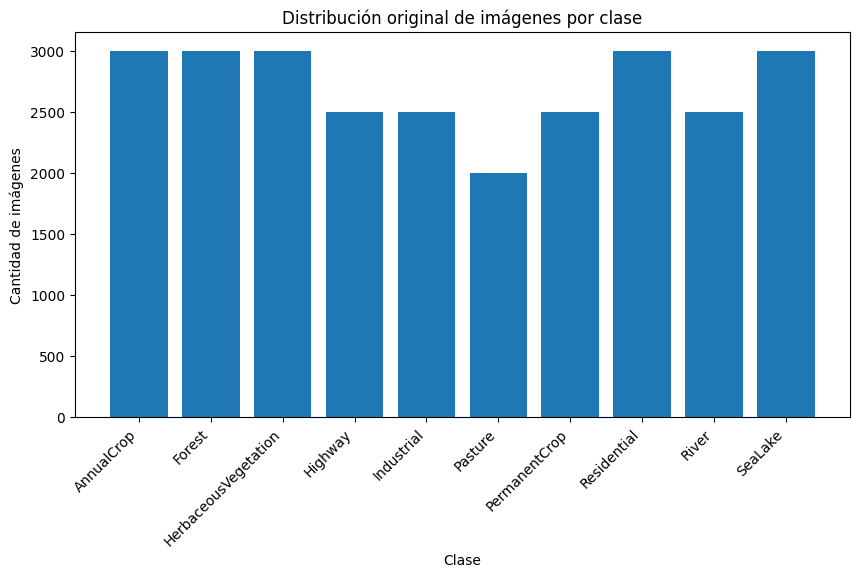

,count
clase,
AnnualCrop,3000
Forest,3000
HerbaceousVegetation,3000
Highway,2500
Industrial,2500
Pasture,2000
PermanentCrop,2500
Residential,3000
River,2500


In [9]:
conteo_original = df["clase"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(conteo_original.index, conteo_original.values)
plt.title("Distribución original de imágenes por clase")
plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=45, ha="right")
plt.show()

conteo_original

In [10]:
IMAGENES_POR_CLASE = 300

df_reducido = (
    df.groupby("clase", group_keys=False)
      .apply(lambda x: x.sample(n=min(IMAGENES_POR_CLASE, len(x)), random_state=SEED))
      .reset_index(drop=True)
)

print("Cantidad total de imágenes reducidas:", len(df_reducido))
print("Distribución reducida:")
print(df_reducido["clase"].value_counts().sort_index())

Cantidad total de imágenes reducidas: 3000
Distribución reducida:
clase
AnnualCrop              300
Forest                  300
HerbaceousVegetation    300
Highway                 300
Industrial              300
Pasture                 300
PermanentCrop           300
Residential             300
River                   300
SeaLake                 300
Name: count, dtype: int64


/tmp/ipykernel_3162/1780356875.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(IMAGENES_POR_CLASE, len(x)), random_state=SEED))


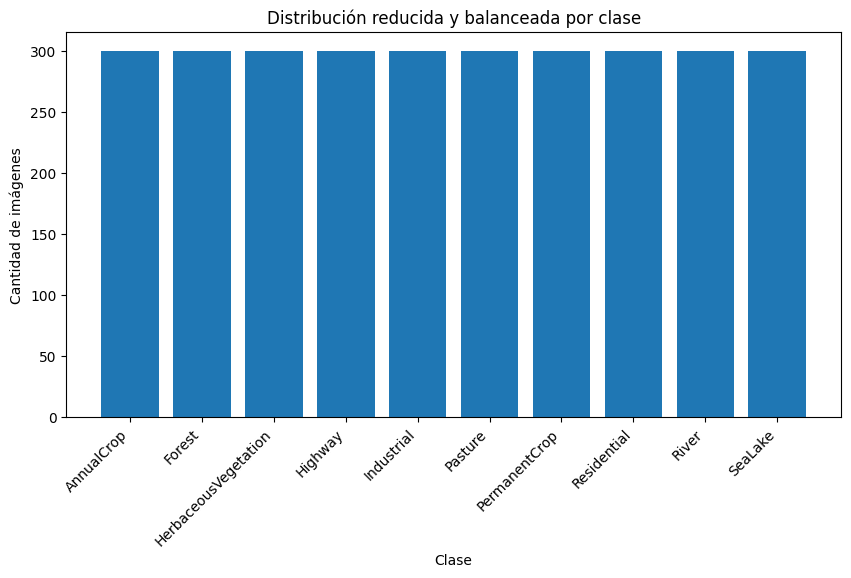

In [11]:
conteo_reducido = df_reducido["clase"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(conteo_reducido.index, conteo_reducido.values)
plt.title("Distribución reducida y balanceada por clase")
plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=45, ha="right")
plt.show()

In [12]:
train_df, temp_df = train_test_split(
    df_reducido,
    test_size=0.30,
    stratify=df_reducido["clase"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["clase"],
    random_state=SEED
)

print("Entrenamiento:", train_df.shape)
print("Validación:", val_df.shape)
print("Prueba:", test_df.shape)

print("\nDistribución entrenamiento:")
print(train_df["clase"].value_counts().sort_index())

print("\nDistribución validación:")
print(val_df["clase"].value_counts().sort_index())

print("\nDistribución prueba:")
print(test_df["clase"].value_counts().sort_index())

Entrenamiento: (2100, 2)
Validación: (450, 2)
Prueba: (450, 2)

Distribución entrenamiento:
clase
AnnualCrop              210
Forest                  210
HerbaceousVegetation    210
Highway                 210
Industrial              210
Pasture                 210
PermanentCrop           210
Residential             210
River                   210
SeaLake                 210
Name: count, dtype: int64

Distribución validación:
clase
AnnualCrop              45
Forest                  45
HerbaceousVegetation    45
Highway                 45
Industrial              45
Pasture                 45
PermanentCrop           45
Residential             45
River                   45
SeaLake                 45
Name: count, dtype: int64

Distribución prueba:
clase
AnnualCrop              45
Forest                  45
HerbaceousVegetation    45
Highway                 45
Industrial              45
Pasture                 45
PermanentCrop           45
Residential             45
River                   

In [13]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

datagen_simple = ImageDataGenerator(rescale=1./255)

train_gen_simple = datagen_simple.flow_from_dataframe(
    train_df,
    x_col="filepath",
    y_col="clase",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_gen = datagen_simple.flow_from_dataframe(
    val_df,
    x_col="filepath",
    y_col="clase",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_gen = datagen_simple.flow_from_dataframe(
    test_df,
    x_col="filepath",
    y_col="clase",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=False
)

NUM_CLASSES = len(train_gen_simple.class_indices)

print("Cantidad de clases:", NUM_CLASSES)
print("Índices de clases:", train_gen_simple.class_indices)

Found 2100 validated image filenames belonging to 10 classes.
Found 450 validated image filenames belonging to 10 classes.
Found 450 validated image filenames belonging to 10 classes.
Cantidad de clases: 10
Índices de clases: {'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}


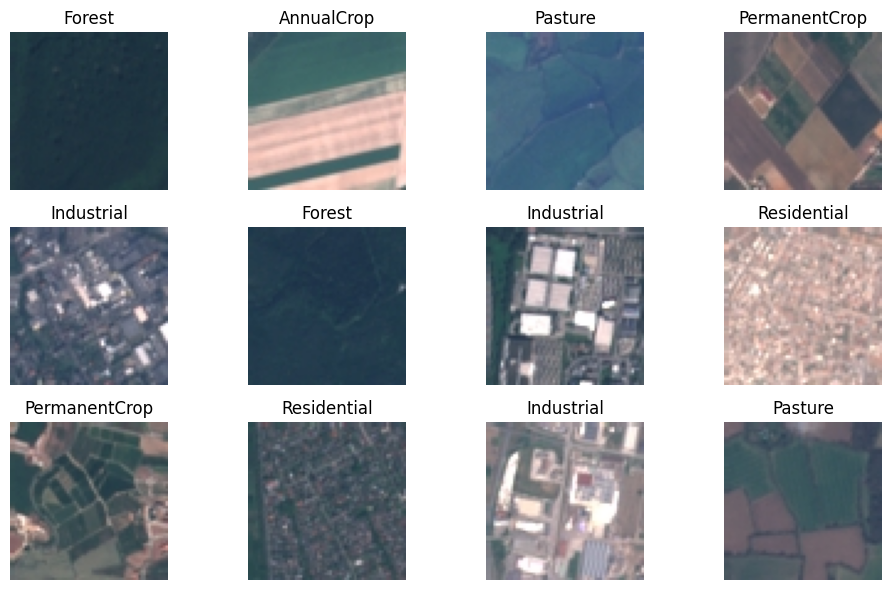

In [14]:
imagenes, etiquetas = next(train_gen_simple)

class_indices = train_gen_simple.class_indices
idx_to_class = {v: k for k, v in class_indices.items()}

plt.figure(figsize=(10, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(imagenes[i])
    clase_idx = np.argmax(etiquetas[i])
    plt.title(idx_to_class[clase_idx])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
def graficar_historial(history, titulo):
    acc = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, acc, label="Entrenamiento")
    plt.plot(epochs, val_acc, label="Validación")
    plt.title(f"Accuracy - {titulo}")
    plt.xlabel("Época")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, loss, label="Entrenamiento")
    plt.plot(epochs, val_loss, label="Validación")
    plt.title(f"Loss - {titulo}")
    plt.xlabel("Época")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

In [16]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

## Modelo 1: CNN simple (línea base)

**¿Por qué se crea este modelo?**

Antes de probar arquitecturas más complejas, es necesario establecer una **línea base (baseline)**: un modelo simple que sirva como punto de referencia para medir si los cambios posteriores realmente mejoran el rendimiento.

El Modelo 1 utiliza la estructura mínima clásica de una CNN:

- Dos bloques de `Conv2D + MaxPooling2D`, que permiten extraer características visuales jerárquicas: el primer bloque aprende bordes y contrastes simples, y el segundo combina esos rasgos en patrones más complejos (texturas, formas).
- `Flatten + Dense(128)` como clasificador sobre las características extraídas.
- Capa de salida `Dense(10)` con activación **softmax**, adecuada para clasificación multiclase porque convierte las salidas en una distribución de probabilidad sobre las 10 clases.
- Pérdida `categorical_crossentropy`, la función estándar para clasificación multiclase con etiquetas one-hot.
- Optimizador **Adam**, elegido por su buen comportamiento por defecto sin necesidad de ajustar manualmente el learning rate en una primera prueba.

Si este modelo simple ya logra aprender, los siguientes experimentos podrán enfocarse en mejorar la generalización.

In [17]:
def crear_modelo_1():
    model = models.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

modelo_1 = crear_modelo_1()
modelo_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,626,442 (6.20 MB)

 Trainable params: 1,626,442 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 14s 176ms/step - accuracy: 0.3086 - loss: 1.7336 - val_accuracy: 0.4489 - val_loss: 1.4494
Epoch 2/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 178ms/step - accuracy: 0.4838 - loss: 1.3351 - val_accuracy: 0.5222 - val_loss: 1.3076
Epoch 3/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 181ms/step - accuracy: 0.5410 - loss: 1.2146 - val_accuracy: 0.5244 - val_loss: 1.3192
Epoch 4/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 178ms/step - accuracy: 0.5843 - loss: 1.1033 - val_accuracy: 0.5600 - val_loss: 1.1493
Epoch 5/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 183ms/step - accuracy: 0.6533 - loss: 0.9613 - val_accuracy: 0.5778 - val_loss: 1.1171
Epoch 6/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 182ms/step - accuracy: 0.6843 - loss: 0.8719 - val_accuracy: 0.5800 - val_loss: 1.1263
Epoch 7/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 176ms/step - accuracy: 0.7138 - loss: 0.7990 - val_accuracy: 0.6422 - val_loss: 1.0564
Epoch 8/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 180ms/step - accuracy: 0.7767 - loss: 0.6465 - val_accuracy: 0.

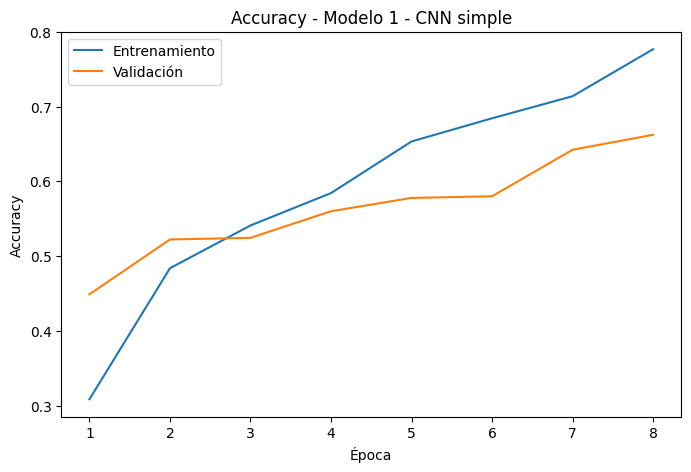

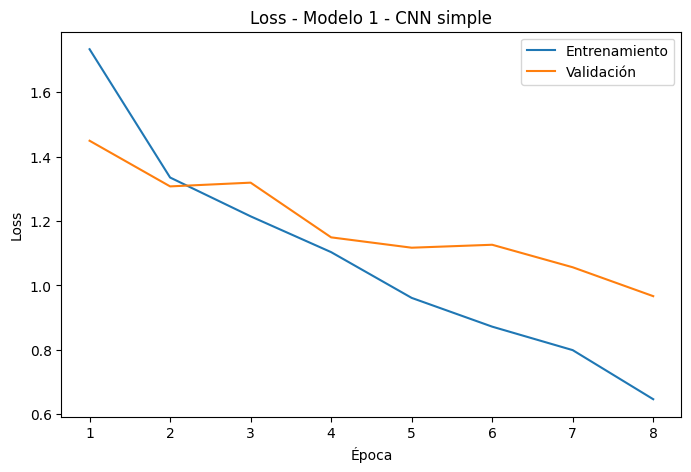

In [18]:
EPOCHS = 8

history_1 = modelo_1.fit(
    train_gen_simple,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

graficar_historial(history_1, "Modelo 1 - CNN simple")

### Conclusión del Modelo 1

El modelo aprendió de forma sostenida durante las 8 épocas: la accuracy de entrenamiento subió de 0.31 a 0.78 y la de validación llegó a 0.66, con una **accuracy de prueba de 0.7067**.

Observaciones sobre las curvas:

- Ambas curvas (entrenamiento y validación) crecen de manera consistente, lo que indica que el modelo está aprendiendo patrones reales y no memorizando.
- Hacia las últimas épocas se abre una **brecha entre entrenamiento (0.78) y validación (0.66)**, un primer signo de sobreajuste incipiente.
- Las curvas todavía no se estabilizaron al finalizar la época 8, lo que sugiere que el modelo podría seguir mejorando con más épocas de entrenamiento.

Este resultado se toma como referencia para los siguientes experimentos.

## Modelo 2: CNN más profunda con Dropout

**¿Por qué se crea este modelo?**

El Modelo 1 mostró una brecha entre entrenamiento y validación. Para intentar reducirla, este experimento introduce dos cambios:

- **Una capa convolucional adicional** (tercer bloque con 128 filtros), para aumentar la capacidad de extraer características más complejas.
- **Dropout** en varios puntos de la red (0.25 luego de los bloques convolucionales y 0.50 antes de la salida). El Dropout apaga neuronas al azar durante el entrenamiento, lo que obliga a la red a no depender de neuronas específicas y suele mejorar la generalización.
- Se agrega `padding="same"` para conservar las dimensiones espaciales y no perder información en los bordes.

La hipótesis es que la combinación de mayor profundidad y regularización debería mejorar la generalización respecto del Modelo 1.

In [19]:
def crear_modelo_2():
    model = models.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.50),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

modelo_2 = crear_modelo_2()
modelo_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 276ms/step - accuracy: 0.1800 - loss: 2.1161 - val_accuracy: 0.2978 - val_loss: 1.8692
Epoch 2/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 19s 293ms/step - accuracy: 0.3100 - loss: 1.7968 - val_accuracy: 0.4222 - val_loss: 1.6294
Epoch 3/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 19s 286ms/step - accuracy: 0.3710 - loss: 1.6463 - val_accuracy: 0.5200 - val_loss: 1.5256


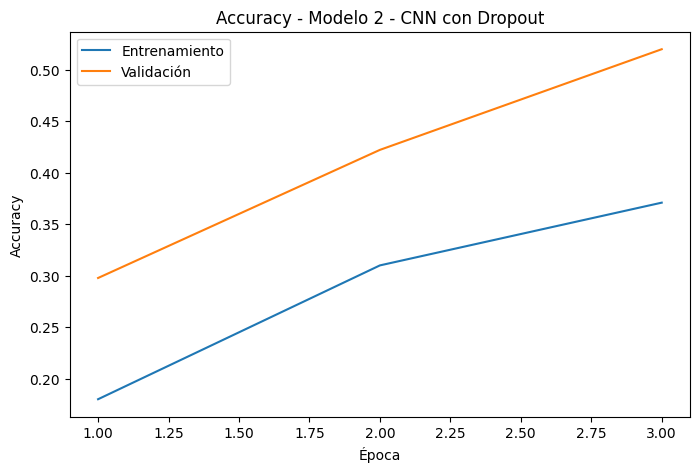

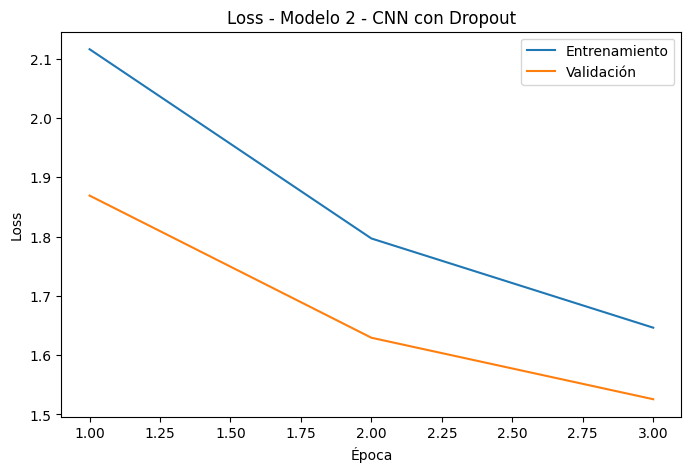

In [20]:
history_2 = modelo_2.fit(
    train_gen_simple,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

graficar_historial(history_2, "Modelo 2 - CNN con Dropout")

### Conclusión del Modelo 2

El experimento **no produjo el resultado esperado**: el entrenamiento se cortó tempranamente (solo 3 épocas registradas) y la accuracy de prueba fue de apenas **0.2822**.

Interpretación:

- La cantidad de Dropout aplicada (tres capas, una de ellas de 0.50) resultó **excesiva para una muestra tan chica** (300 imágenes por clase, ~2.100 de entrenamiento). El modelo aprendía muy lentamente: en la época 3 todavía estaba en 0.37 de accuracy de entrenamiento.
- El modelo quedó claramente en situación de **subajuste (underfitting)**: ni siquiera llegó a ajustarse bien a los datos de entrenamiento.
- La lección de este experimento es que la regularización fuerte necesita más datos y/o más épocas de entrenamiento para dar resultado.

Conclusión: agregar regularización agresiva sin aumentar los datos ni el tiempo de entrenamiento empeoró el modelo.

## Modelo 3: BatchNormalization + Dropout + GlobalAveragePooling

**¿Por qué se crea este modelo?**

Este experimento prueba técnicas adicionales habituales en CNNs modernas:

- **BatchNormalization** después de cada convolución: normaliza las activaciones de cada lote, lo que en teoría estabiliza y acelera el entrenamiento.
- **GlobalAveragePooling2D** en lugar de Flatten: reduce drásticamente la cantidad de parámetros del clasificador (promedia cada mapa de características en un solo valor), lo que debería disminuir el riesgo de sobreajuste.
- Se mantiene el Dropout del Modelo 2 y se fija explícitamente el learning rate de Adam en 0.001.

La hipótesis es que la normalización por lotes debería permitir un entrenamiento más estable que el del Modelo 2.

In [21]:
def crear_modelo_3():
    model = models.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.50),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

modelo_3 = crear_modelo_3()
modelo_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,946 (437.29 KB)

 Trainable params: 111,498 (435.54 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 29s 380ms/step - accuracy: 0.4462 - loss: 1.5833 - val_accuracy: 0.1422 - val_loss: 2.4280
Epoch 2/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 25s 377ms/step - accuracy: 0.5662 - loss: 1.2001 - val_accuracy: 0.1000 - val_loss: 3.0272
Epoch 3/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 26s 387ms/step - accuracy: 0.6276 - loss: 1.0523 - val_accuracy: 0.0822 - val_loss: 3.7507


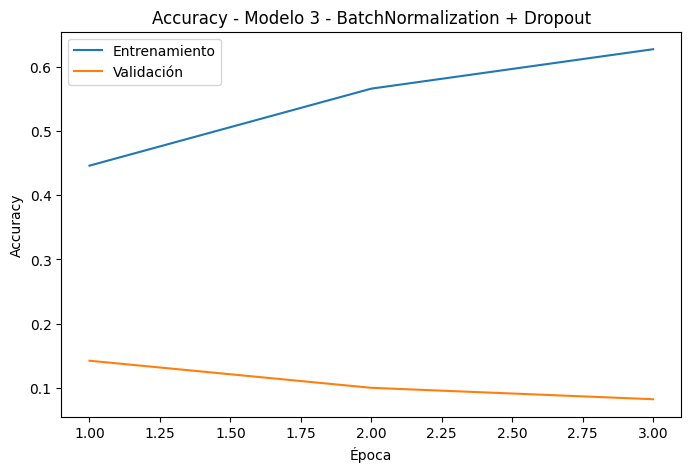

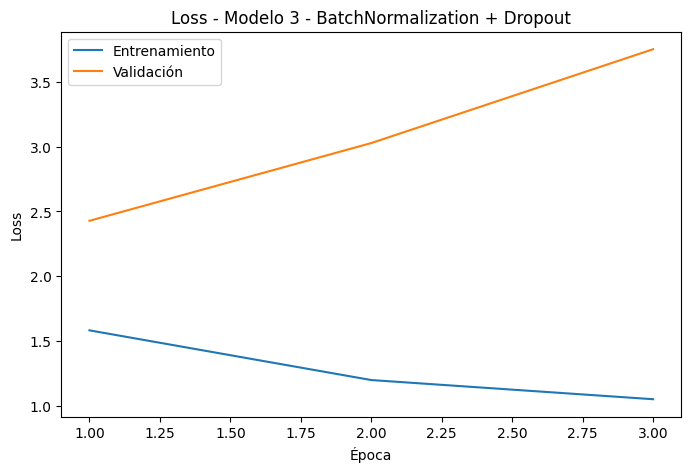

In [22]:
history_3 = modelo_3.fit(
    train_gen_simple,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

graficar_historial(history_3, "Modelo 3 - BatchNormalization + Dropout")

### Conclusión del Modelo 3

El resultado fue el **peor de todo el bloque**: accuracy de prueba de **0.1422**, apenas por encima del azar (0.10 para 10 clases).

Interpretación de las curvas:

- La accuracy de **entrenamiento** subió con normalidad (0.45 → 0.63), pero la de **validación se desplomó** (0.14 → 0.08) y la loss de validación creció hasta 3.75.
- Esta divergencia tan marcada es típica de un problema con **BatchNormalization en entrenamientos cortos y con pocos datos**: las estadísticas (media y varianza) que BatchNorm acumula durante el entrenamiento todavía no se estabilizaron, y en la fase de validación (donde se usan esas estadísticas acumuladas en lugar de las del lote) las activaciones quedan mal normalizadas.
- El EarlyStopping cortó el entrenamiento antes de que esas estadísticas pudieran estabilizarse.

Conclusión: en esta configuración (muestra chica + pocas épocas), BatchNormalization perjudicó la generalización. Esto no significa que la técnica sea mala en sí misma, sino que requiere condiciones distintas (más datos y más épocas). Esta observación se retomará en el tercer bloque experimental.

## Comparación de resultados del primer bloque

A continuación se consolidan las métricas de los tres modelos para compararlos de forma directa. Se reporta la mejor accuracy de validación, la menor loss de validación, y la accuracy y loss sobre el conjunto de prueba, que es la medida más representativa del rendimiento real.

In [23]:
def obtener_metricas(nombre, model, history, test_gen):
    test_loss, test_acc = model.evaluate(test_gen, verbose=0)

    mejor_val_acc = max(history.history["val_accuracy"])
    menor_val_loss = min(history.history["val_loss"])

    return {
        "Modelo": nombre,
        "Mejor val_accuracy": mejor_val_acc,
        "Menor val_loss": menor_val_loss,
        "Test accuracy": test_acc,
        "Test loss": test_loss,
        "Épocas entrenadas": len(history.history["accuracy"])
    }

resultados = []

resultados.append(obtener_metricas("Modelo 1 - CNN simple", modelo_1, history_1, test_gen))
resultados.append(obtener_metricas("Modelo 2 - CNN + Dropout", modelo_2, history_2, test_gen))
resultados.append(obtener_metricas("Modelo 3 - BatchNorm + Dropout", modelo_3, history_3, test_gen))

df_resultados = pd.DataFrame(resultados)

df_resultados

,Modelo,Mejor val_accuracy,Menor val_loss,Test accuracy,Test loss,Épocas entrenadas
0,Modelo 1 - CNN simple,0.662222,0.966623,0.706667,0.870919,8
1,Modelo 2 - CNN + Dropout,0.520000,1.525639,0.282222,1.883321,3
2,Modelo 3 - BatchNorm + Dropout,0.142222,2.427975,0.142222,2.426757,3


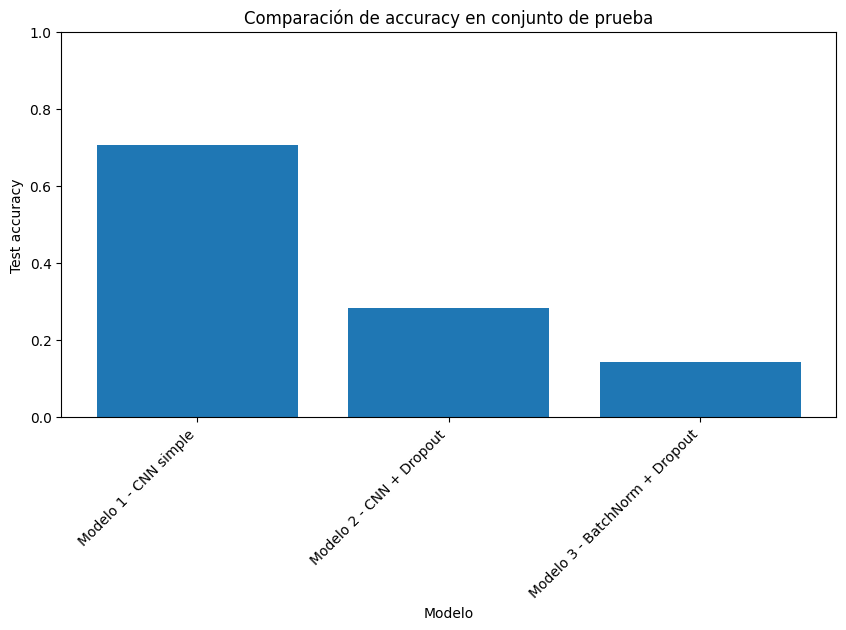

In [24]:
plt.figure(figsize=(10, 5))
plt.bar(df_resultados["Modelo"], df_resultados["Test accuracy"])
plt.title("Comparación de accuracy en conjunto de prueba")
plt.xlabel("Modelo")
plt.ylabel("Test accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.show()

In [25]:
mejor_fila = df_resultados.sort_values("Test accuracy", ascending=False).iloc[0]
mejor_modelo_nombre = mejor_fila["Modelo"]

print("Mejor modelo según accuracy en test:")
print(mejor_modelo_nombre)

if mejor_modelo_nombre.startswith("Modelo 1"):
    mejor_modelo = modelo_1
elif mejor_modelo_nombre.startswith("Modelo 2"):
    mejor_modelo = modelo_2
else:
    mejor_modelo = modelo_3

Mejor modelo según accuracy en test:
Modelo 1 - CNN simple


15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step


<Figure size 1000x1000 with 0 Axes>

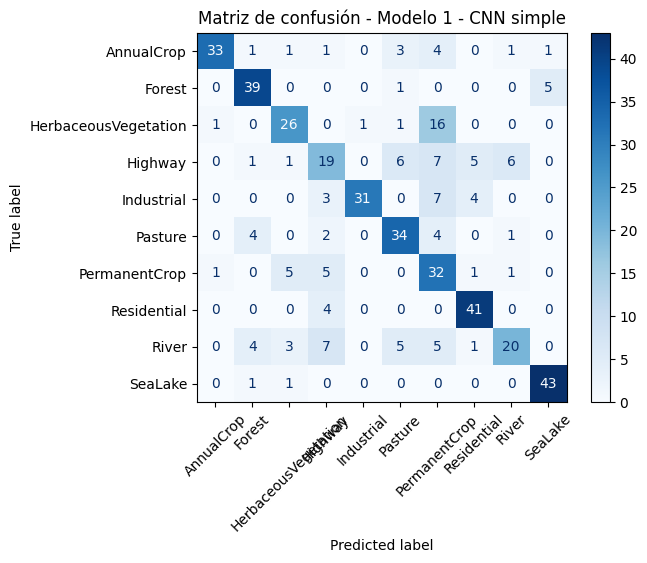

In [26]:
test_gen.reset()

predicciones = mejor_modelo.predict(test_gen)
y_pred = np.argmax(predicciones, axis=1)
y_true = test_gen.classes

nombres_clases = list(test_gen.class_indices.keys())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Matriz de confusión - {mejor_modelo_nombre}")
plt.show()

In [27]:
reporte = classification_report(
    y_true,
    y_pred,
    target_names=nombres_clases,
    output_dict=True
)

df_reporte = pd.DataFrame(reporte).transpose()
df_reporte

,precision,recall,f1-score,support
AnnualCrop,0.942857,0.733333,0.825000,45.000000
Forest,0.780000,0.866667,0.821053,45.000000
HerbaceousVegetation,0.702703,0.577778,0.634146,45.000000
Highway,0.463415,0.422222,0.441860,45.000000
Industrial,0.968750,0.688889,0.805195,45.000000
Pasture,0.680000,0.755556,0.715789,45.000000
PermanentCrop,0.426667,0.711111,0.533333,45.000000
Residential,0.788462,0.911111,0.845361,45.000000
River,0.689655,0.444444,0.540541,45.000000
SeaLake,0.877551,0.955556,0.914894,45.000000


In [28]:
print(classification_report(
    y_true,
    y_pred,
    target_names=nombres_clases
))

                      precision    recall  f1-score   support

          AnnualCrop       0.94      0.73      0.82        45
              Forest       0.78      0.87      0.82        45
HerbaceousVegetation       0.70      0.58      0.63        45
             Highway       0.46      0.42      0.44        45
          Industrial       0.97      0.69      0.81        45
             Pasture       0.68      0.76      0.72        45
       PermanentCrop       0.43      0.71      0.53        45
         Residential       0.79      0.91      0.85        45
               River       0.69      0.44      0.54        45
             SeaLake       0.88      0.96      0.91        45

            accuracy                           0.71       450
           macro avg       0.73      0.71      0.71       450
        weighted avg       0.73      0.71      0.71       450



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step


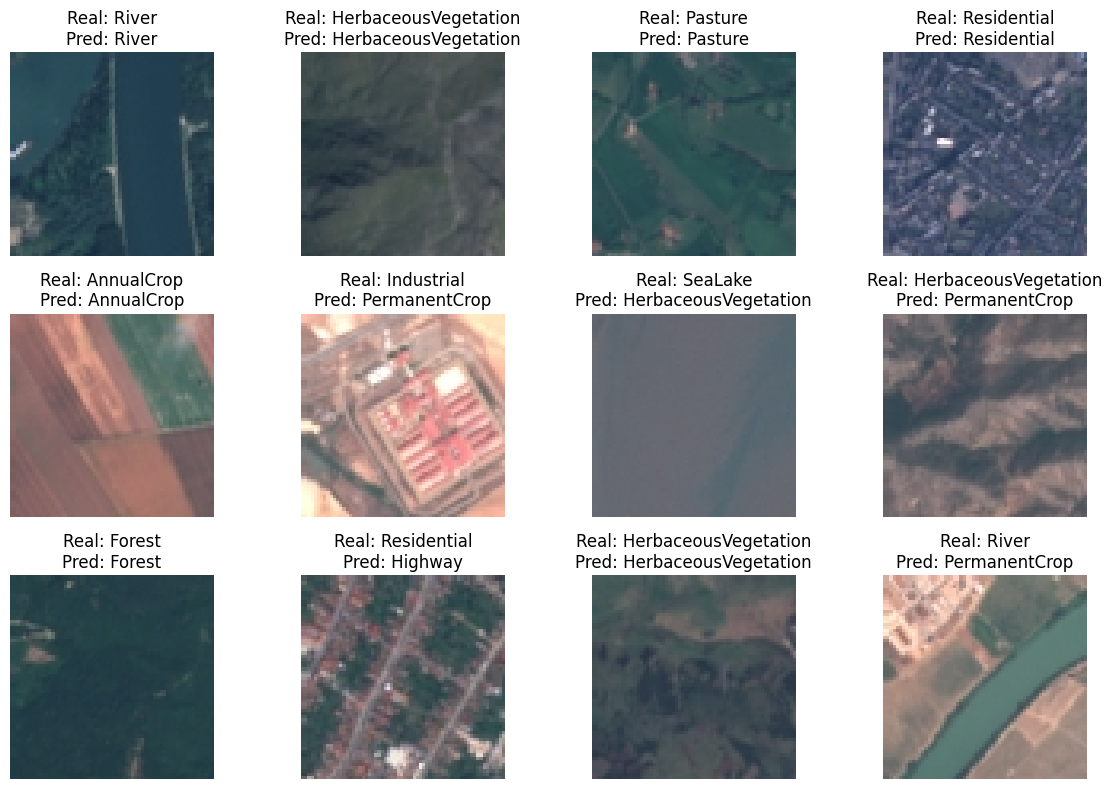

In [29]:
test_gen.reset()

imagenes_test, etiquetas_test = next(test_gen)
preds = mejor_modelo.predict(imagenes_test)

plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(imagenes_test[i])

    real_idx = np.argmax(etiquetas_test[i])
    pred_idx = np.argmax(preds[i])

    real = idx_to_class[real_idx]
    pred = idx_to_class[pred_idx]

    plt.title(f"Real: {real}\nPred: {pred}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Decisión para continuar la experimentación

A partir de los primeros resultados, el Modelo 1 fue el que obtuvo mejor desempeño general. Alcanzó una accuracy de prueba de 0.7067, mientras que los modelos más complejos no lograron mejorar ese resultado.

El Modelo 2, que incorporaba mayor profundidad y Dropout, no llegó a entrenar de manera suficiente y obtuvo una accuracy de prueba baja. Esto puede deberse a que la regularización fue demasiado fuerte para una muestra reducida de 300 imágenes por clase.

El Modelo 3, con BatchNormalization y Dropout, presentó una diferencia muy marcada entre entrenamiento y validación. La accuracy de entrenamiento aumentó, pero la accuracy de validación se mantuvo muy baja y la loss de validación aumentó. Esto indica que, con esta configuración, el modelo no generalizó correctamente.

Por este motivo, la siguiente etapa experimental no consistirá en agregar complejidad de manera automática, sino en comenzar un nuevo bloque de pruebas aumentando la cantidad de imágenes por clase. La hipótesis es que una muestra más amplia puede ofrecer mayor variedad visual y permitir que los modelos aprendan patrones más representativos.

En el nuevo bloque se mantiene un preprocesamiento básico, sin data augmentation, para evaluar primero el efecto de aumentar la cantidad de datos y ajustar la arquitectura.

# Segundo bloque experimental

## Aumento de cantidad de imágenes por clase

En el primer bloque experimental se trabajó con 300 imágenes por clase.  
Para continuar la experimentación, se aumenta la muestra a 500 imágenes por clase.

Esta decisión busca mejorar la variedad de ejemplos disponibles para el entrenamiento sin utilizar todavía el dataset completo. De esta manera, se mantiene un tiempo de entrenamiento razonable y se puede evaluar si el aumento de datos mejora el desempeño de los modelos.

La muestra continúa siendo balanceada, ya que se selecciona la misma cantidad de imágenes para cada una de las 10 clases.

In [30]:
IMAGENES_POR_CLASE_NUEVO = 500

df_reducido_nuevo = (
    df.groupby("clase", group_keys=False)
      .apply(lambda x: x.sample(n=min(IMAGENES_POR_CLASE_NUEVO, len(x)), random_state=SEED))
      .reset_index(drop=True)
)

print("Cantidad de imágenes por clase:", IMAGENES_POR_CLASE_NUEVO)
print("Cantidad total de imágenes:", len(df_reducido_nuevo))
print("\nDistribución por clase:")
print(df_reducido_nuevo["clase"].value_counts().sort_index())

Cantidad de imágenes por clase: 500
Cantidad total de imágenes: 5000

Distribución por clase:
clase
AnnualCrop              500
Forest                  500
HerbaceousVegetation    500
Highway                 500
Industrial              500
Pasture                 500
PermanentCrop           500
Residential             500
River                   500
SeaLake                 500
Name: count, dtype: int64


/tmp/ipykernel_3162/1464559933.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(IMAGENES_POR_CLASE_NUEVO, len(x)), random_state=SEED))


In [31]:
train_df_nuevo, temp_df_nuevo = train_test_split(
    df_reducido_nuevo,
    test_size=0.30,
    stratify=df_reducido_nuevo["clase"],
    random_state=SEED
)

val_df_nuevo, test_df_nuevo = train_test_split(
    temp_df_nuevo,
    test_size=0.50,
    stratify=temp_df_nuevo["clase"],
    random_state=SEED
)

print("Nuevo conjunto de entrenamiento:", train_df_nuevo.shape)
print("Nuevo conjunto de validación:", val_df_nuevo.shape)
print("Nuevo conjunto de prueba:", test_df_nuevo.shape)

print("\nDistribución entrenamiento:")
print(train_df_nuevo["clase"].value_counts().sort_index())

print("\nDistribución validación:")
print(val_df_nuevo["clase"].value_counts().sort_index())

print("\nDistribución prueba:")
print(test_df_nuevo["clase"].value_counts().sort_index())

Nuevo conjunto de entrenamiento: (3500, 2)
Nuevo conjunto de validación: (750, 2)
Nuevo conjunto de prueba: (750, 2)

Distribución entrenamiento:
clase
AnnualCrop              350
Forest                  350
HerbaceousVegetation    350
Highway                 350
Industrial              350
Pasture                 350
PermanentCrop           350
Residential             350
River                   350
SeaLake                 350
Name: count, dtype: int64

Distribución validación:
clase
AnnualCrop              75
Forest                  75
HerbaceousVegetation    75
Highway                 75
Industrial              75
Pasture                 75
PermanentCrop           75
Residential             75
River                   75
SeaLake                 75
Name: count, dtype: int64

Distribución prueba:
clase
AnnualCrop              75
Forest                  75
HerbaceousVegetation    75
Highway                 75
Industrial              75
Pasture                 75
PermanentCrop           

## Nueva división de datos

Con 500 imágenes por clase se obtiene un total de 5.000 imágenes.

La división se mantiene igual que en el primer bloque:

- 70% para entrenamiento.
- 15% para validación.
- 15% para prueba.

Se utiliza estratificación para conservar la misma proporción de clases en cada subconjunto.

In [32]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

datagen_simple = ImageDataGenerator(rescale=1./255)

train_gen_nuevo = datagen_simple.flow_from_dataframe(
    train_df_nuevo,
    x_col="filepath",
    y_col="clase",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_gen_nuevo = datagen_simple.flow_from_dataframe(
    val_df_nuevo,
    x_col="filepath",
    y_col="clase",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_gen_nuevo = datagen_simple.flow_from_dataframe(
    test_df_nuevo,
    x_col="filepath",
    y_col="clase",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=False
)

NUM_CLASSES = len(train_gen_nuevo.class_indices)

print("Cantidad de clases:", NUM_CLASSES)
print("Índices de clases:", train_gen_nuevo.class_indices)

Found 3500 validated image filenames belonging to 10 classes.
Found 750 validated image filenames belonging to 10 classes.
Found 750 validated image filenames belonging to 10 classes.
Cantidad de clases: 10
Índices de clases: {'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}


# Modelos del segundo bloque experimental

En este segundo bloque se entrena nuevamente una serie de modelos CNN, pero ahora utilizando una muestra ampliada de 500 imágenes por clase.

El objetivo principal es analizar si el aumento de datos mejora el rendimiento respecto del primer bloque, donde se utilizaron 300 imágenes por clase.

No se incorpora data augmentation en esta etapa. La intención es mantener un preprocesamiento básico y observar primero el efecto de aumentar la cantidad de imágenes y ajustar moderadamente la arquitectura.

Los modelos de este bloque son:

- Modelo 4: repetición del mejor modelo anterior, pero con más datos.
- Modelo 5: CNN simple con Dropout suave y learning rate menor.
- Modelo 6: CNN con una capa convolucional adicional, sin BatchNormalization.

In [33]:
def crear_callbacks_bloque2():
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        )
    ]

## Modelo 4: repetición del modelo base con más datos

El Modelo 4 retoma la arquitectura del Modelo 1, que fue la mejor en el primer bloque experimental.

La diferencia principal no está en la arquitectura, sino en la cantidad de imágenes utilizadas. En este caso, el modelo se entrena con 500 imágenes por clase en lugar de 300.

Este experimento permite analizar si el aumento de datos mejora el rendimiento del modelo sin incorporar todavía modificaciones más complejas.

In [34]:
def crear_modelo_4():
    model = models.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

modelo_4 = crear_modelo_4()
modelo_4.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,626,442 (6.20 MB)

 Trainable params: 1,626,442 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 22s 189ms/step - accuracy: 0.2786 - loss: 1.8554 - val_accuracy: 0.4307 - val_loss: 1.4809
Epoch 2/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 19s 171ms/step - accuracy: 0.4960 - loss: 1.3559 - val_accuracy: 0.5000 - val_loss: 1.3479
Epoch 3/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 21s 189ms/step - accuracy: 0.5489 - loss: 1.2013 - val_accuracy: 0.5920 - val_loss: 1.1163
Epoch 4/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 19s 170ms/step - accuracy: 0.5980 - loss: 1.0819 - val_accuracy: 0.5000 - val_loss: 1.2742
Epoch 5/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 20s 186ms/step - accuracy: 0.6534 - loss: 0.9489 - val_accuracy: 0.6600 - val_loss: 0.9356
Epoch 6/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 19s 173ms/step - accuracy: 0.7120 - loss: 0.8507 - val_accuracy: 0.6827 - val_loss: 0.8767
Epoch 7/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 20s 181ms/step - accuracy: 0.7346 - loss: 0.7401 - val_accuracy: 0.6733 - val_loss: 0.8612
Epoch 8/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 18s 167ms/step - accuracy: 0.7749 - loss: 0

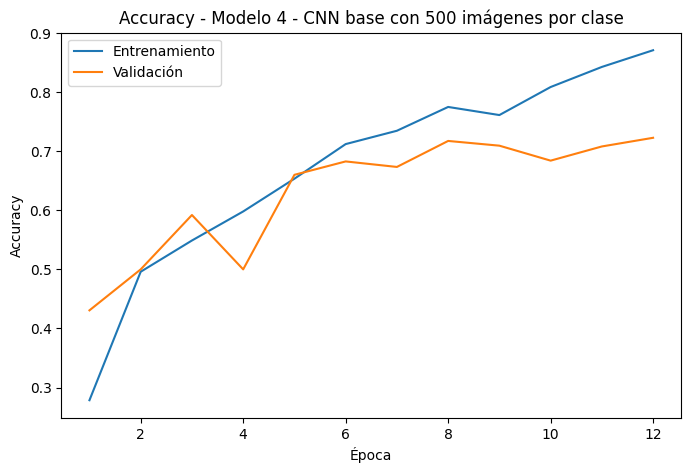

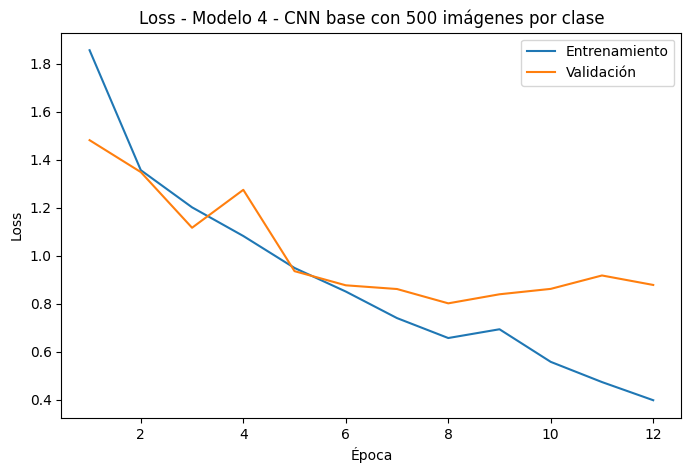

In [35]:
EPOCHS_BLOQUE2 = 12

history_4 = modelo_4.fit(
    train_gen_nuevo,
    validation_data=val_gen_nuevo,
    epochs=EPOCHS_BLOQUE2,
    callbacks=crear_callbacks_bloque2()
)

graficar_historial(history_4, "Modelo 4 - CNN base con 500 imágenes por clase")

### Conclusión del Modelo 4

Con 500 imágenes por clase, el mismo modelo base alcanzó una **mejor accuracy de validación de 0.7227** (contra 0.6622 del Modelo 1) y una **accuracy de prueba de 0.6907**.

Observaciones:

- El aumento de datos **mejoró la validación** y permitió entrenar más épocas de forma estable, confirmando parcialmente la hipótesis del bloque.
- La accuracy de prueba quedó levemente por debajo de la del Modelo 1 (0.7067), pero hay que tener en cuenta que **los conjuntos de prueba no son los mismos** (450 vs. 750 imágenes), por lo que la comparación entre bloques es orientativa. Dentro de este bloque, el Modelo 4 funciona como nueva línea base.
- Persiste una brecha entre entrenamiento y validación, lo que indica que sigue habiendo margen para trabajar la generalización.

## Modelo 5: CNN base con Dropout suave y learning rate menor

El Modelo 5 mantiene una arquitectura cercana al modelo base, pero introduce dos modificaciones:

- Dropout de 0.20 antes de la capa de salida.
- Learning rate menor: 0.0005.

La decisión se basa en los resultados del primer bloque. El Modelo 1 aprendió correctamente, pero mostró cierta diferencia entre entrenamiento y validación. Por eso se prueba una regularización suave, sin aplicar un Dropout excesivo como en el Modelo 2.

Además, se reduce el learning rate para que el aprendizaje sea más gradual y estable.

In [36]:
def crear_modelo_5():
    model = models.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.20),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

modelo_5 = crear_modelo_5()
modelo_5.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,626,442 (6.20 MB)

 Trainable params: 1,626,442 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 23s 192ms/step - accuracy: 0.2591 - loss: 1.9039 - val_accuracy: 0.4547 - val_loss: 1.5359
Epoch 2/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 21s 187ms/step - accuracy: 0.4106 - loss: 1.5117 - val_accuracy: 0.5040 - val_loss: 1.3292
Epoch 3/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 41s 191ms/step - accuracy: 0.4940 - loss: 1.3333 - val_accuracy: 0.5613 - val_loss: 1.1998
Epoch 4/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 19s 177ms/step - accuracy: 0.5454 - loss: 1.2299 - val_accuracy: 0.6360 - val_loss: 1.0917
Epoch 5/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 21s 192ms/step - accuracy: 0.5997 - loss: 1.1029 - val_accuracy: 0.5720 - val_loss: 1.1795
Epoch 6/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 20s 179ms/step - accuracy: 0.6406 - loss: 1.0135 - val_accuracy: 0.6973 - val_loss: 0.8978
Epoch 7/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 21s 192ms/step - accuracy: 0.6794 - loss: 0.9267 - val_accuracy: 0.6640 - val_loss: 0.9286
Epoch 8/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 21s 194ms/step - accuracy: 0.6660 - loss: 0

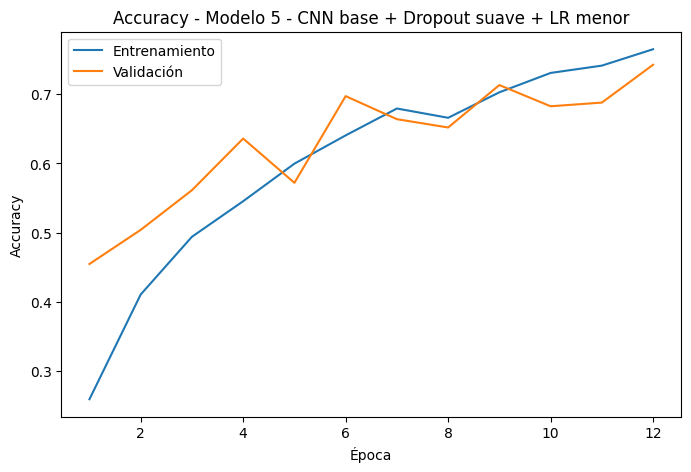

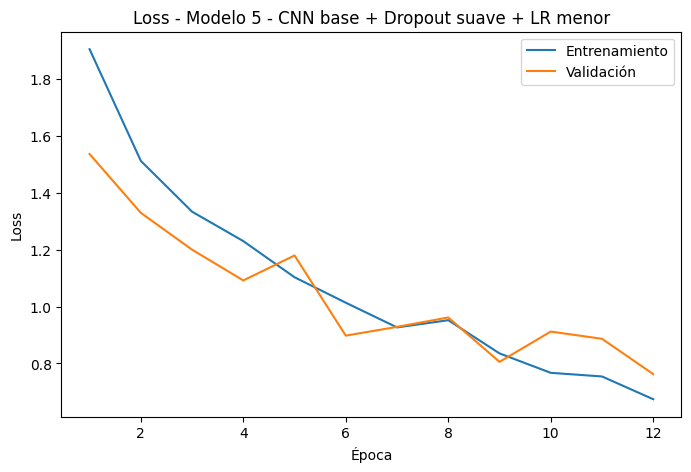

In [37]:
history_5 = modelo_5.fit(
    train_gen_nuevo,
    validation_data=val_gen_nuevo,
    epochs=EPOCHS_BLOQUE2,
    callbacks=crear_callbacks_bloque2()
)

graficar_historial(history_5, "Modelo 5 - CNN base + Dropout suave + LR menor")

### Conclusión del Modelo 5

La combinación de **Dropout suave (0.20)** y **learning rate menor (0.0005)** mejoró el resultado: **accuracy de prueba de 0.7253**, superando al Modelo 4 (0.6907).

Observaciones:

- A diferencia del Modelo 2 (donde el Dropout fuerte impidió aprender), una regularización **moderada** sí ayudó: el modelo aprendió más lento pero de forma más estable.
- El learning rate menor produjo curvas de validación menos oscilantes.
- Este resultado confirma que la regularización es útil, pero su **intensidad debe ser proporcional a la cantidad de datos disponibles**.

## Modelo 6: CNN con una capa convolucional adicional

El Modelo 6 incorpora una capa convolucional adicional respecto del modelo base. La intención es aumentar la capacidad del modelo para extraer características visuales más complejas.

A diferencia del Modelo 3 del primer bloque, en este caso no se utiliza BatchNormalization, ya que en el experimento anterior no mejoró la generalización. Tampoco se aplica data augmentation.

El objetivo es probar una arquitectura más profunda, pero todavía controlada.

In [38]:
def crear_modelo_6():
    model = models.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.25),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

modelo_6 = crear_modelo_6()
modelo_6.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 33s 289ms/step - accuracy: 0.2680 - loss: 1.8627 - val_accuracy: 0.3747 - val_loss: 1.5512
Epoch 2/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 33s 296ms/step - accuracy: 0.4246 - loss: 1.4737 - val_accuracy: 0.4720 - val_loss: 1.3811
Epoch 3/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 31s 279ms/step - accuracy: 0.4989 - loss: 1.3235 - val_accuracy: 0.4533 - val_loss: 1.4281
Epoch 4/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 32s 288ms/step - accuracy: 0.5371 - loss: 1.2535 - val_accuracy: 0.5627 - val_loss: 1.1510
Epoch 5/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 32s 286ms/step - accuracy: 0.5854 - loss: 1.1467 - val_accuracy: 0.5947 - val_loss: 1.0935
Epoch 6/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 33s 297ms/step - accuracy: 0.6057 - loss: 1.0869 - val_accuracy: 0.6040 - val_loss: 1.0285
Epoch 7/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 31s 285ms/step - accuracy: 0.6563 - loss: 0.9584 - val_accuracy: 0.6453 - val_loss: 0.9951
Epoch 8/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 32s 293ms/step - accuracy: 0.6674 - loss: 0

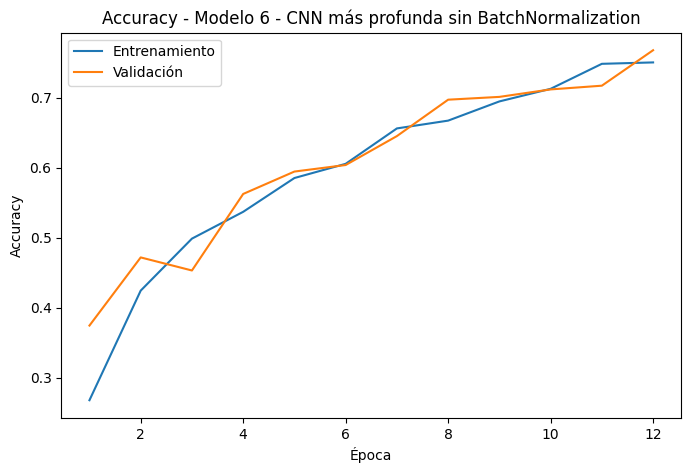

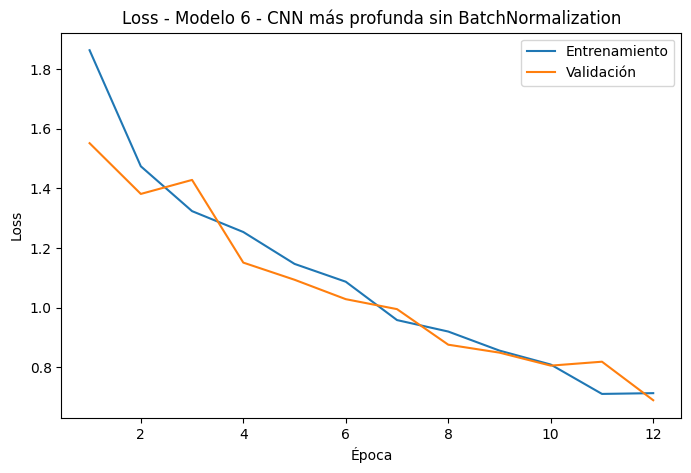

In [39]:
history_6 = modelo_6.fit(
    train_gen_nuevo,
    validation_data=val_gen_nuevo,
    epochs=EPOCHS_BLOQUE2,
    callbacks=crear_callbacks_bloque2()
)

graficar_historial(history_6, "Modelo 6 - CNN más profunda sin BatchNormalization")

### Conclusión del Modelo 6

El Modelo 6 fue el **mejor del segundo bloque y de todo el trabajo hasta este punto**: **accuracy de prueba de 0.7520** y mejor accuracy de validación de 0.768.

Observaciones:

- La capa convolucional adicional (tercer bloque de 128 filtros) aportó capacidad para extraer patrones más complejos, y con 500 imágenes por clase esa capacidad extra pudo aprovecharse (a diferencia del Modelo 2, donde una red más profunda fracasó con menos datos).
- La ausencia de BatchNormalization evitó el problema de inestabilidad observado en el Modelo 3.
- El Dropout moderado (0.25) antes de la salida ayudó a controlar el sobreajuste sin frenar el aprendizaje.

Conclusión: profundidad moderada + regularización suave + más datos fue la mejor combinación hasta ahora. Esta arquitectura se toma como base para el tercer bloque experimental.

## Comparación de resultados del segundo bloque

Se consolidan las métricas de los Modelos 4, 5 y 6, todos entrenados y evaluados sobre la misma partición de datos (500 imágenes por clase), lo que permite una comparación directa y justa entre ellos.

In [40]:
def obtener_metricas(nombre, model, history, test_gen):
    test_gen.reset()
    test_loss, test_acc = model.evaluate(test_gen, verbose=0)

    mejor_val_acc = max(history.history["val_accuracy"])
    menor_val_loss = min(history.history["val_loss"])

    return {
        "Modelo": nombre,
        "Mejor val_accuracy": mejor_val_acc,
        "Menor val_loss": menor_val_loss,
        "Test accuracy": test_acc,
        "Test loss": test_loss,
        "Épocas entrenadas": len(history.history["accuracy"])
    }

In [41]:
resultados_bloque2 = []

resultados_bloque2.append(
    obtener_metricas("Modelo 4 - CNN base con 500 imágenes", modelo_4, history_4, test_gen_nuevo)
)

resultados_bloque2.append(
    obtener_metricas("Modelo 5 - CNN + Dropout suave + LR menor", modelo_5, history_5, test_gen_nuevo)
)

resultados_bloque2.append(
    obtener_metricas("Modelo 6 - CNN más profunda sin BatchNorm", modelo_6, history_6, test_gen_nuevo)
)

df_resultados_bloque2 = pd.DataFrame(resultados_bloque2)

df_resultados_bloque2.sort_values("Test accuracy", ascending=False)

,Modelo,Mejor val_accuracy,Menor val_loss,Test accuracy,Test loss,Épocas entrenadas
2,Modelo 6 - CNN más profunda sin BatchNorm,0.768000,0.689881,0.752000,0.746740,12
1,Modelo 5 - CNN + Dropout suave + LR menor,0.742667,0.762794,0.725333,0.798244,12
0,Modelo 4 - CNN base con 500 imágenes,0.722667,0.801595,0.690667,0.867768,12


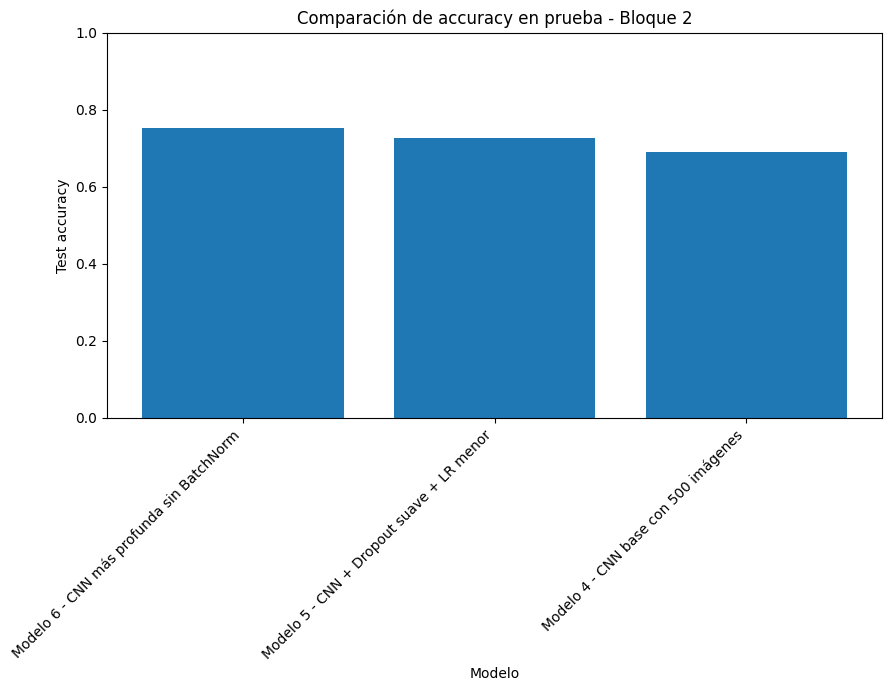

In [42]:
df_bloque2_ordenado = df_resultados_bloque2.sort_values("Test accuracy", ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(df_bloque2_ordenado["Modelo"], df_bloque2_ordenado["Test accuracy"])
plt.title("Comparación de accuracy en prueba - Bloque 2")
plt.xlabel("Modelo")
plt.ylabel("Test accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.show()

In [43]:
df_resultados_bloque1 = df_resultados.copy()
df_resultados_bloque1["Bloque"] = "Bloque 1 - 300 imágenes por clase"

df_resultados_bloque2["Bloque"] = "Bloque 2 - 500 imágenes por clase"

df_comparacion_total = pd.concat(
    [df_resultados_bloque1, df_resultados_bloque2],
    ignore_index=True
)

df_comparacion_total.sort_values("Test accuracy", ascending=False)

,Modelo,Mejor val_accuracy,Menor val_loss,Test accuracy,Test loss,Épocas entrenadas,Bloque
5,Modelo 6 - CNN más profunda sin BatchNorm,0.768000,0.689881,0.752000,0.746740,12,Bloque 2 - 500 imágenes por clase
4,Modelo 5 - CNN + Dropout suave + LR menor,0.742667,0.762794,0.725333,0.798244,12,Bloque 2 - 500 imágenes por clase
0,Modelo 1 - CNN simple,0.662222,0.966623,0.706667,0.870919,8,Bloque 1 - 300 imágenes por clase
3,Modelo 4 - CNN base con 500 imágenes,0.722667,0.801595,0.690667,0.867768,12,Bloque 2 - 500 imágenes por clase
1,Modelo 2 - CNN + Dropout,0.520000,1.525639,0.282222,1.883321,3,Bloque 1 - 300 imágenes por clase
2,Modelo 3 - BatchNorm + Dropout,0.142222,2.427975,0.142222,2.426757,3,Bloque 1 - 300 imágenes por clase


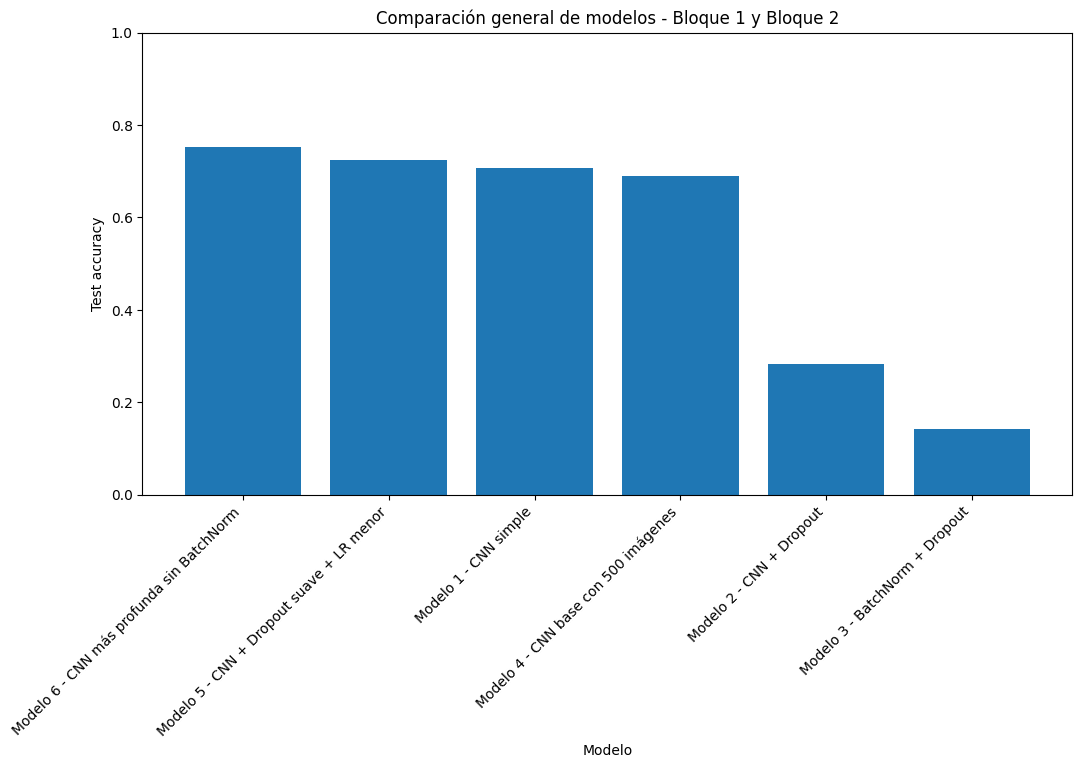

In [44]:
df_total_ordenado = df_comparacion_total.sort_values("Test accuracy", ascending=False)

plt.figure(figsize=(12, 6))
plt.bar(df_total_ordenado["Modelo"], df_total_ordenado["Test accuracy"])
plt.title("Comparación general de modelos - Bloque 1 y Bloque 2")
plt.xlabel("Modelo")
plt.ylabel("Test accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.show()

In [45]:
mejor_fila_bloque2 = df_resultados_bloque2.sort_values("Test accuracy", ascending=False).iloc[0]
mejor_modelo_bloque2_nombre = mejor_fila_bloque2["Modelo"]

print("Mejor modelo del Bloque 2 según accuracy en test:")
print(mejor_modelo_bloque2_nombre)

if mejor_modelo_bloque2_nombre.startswith("Modelo 4"):
    mejor_modelo_bloque2 = modelo_4
    mejor_history_bloque2 = history_4
elif mejor_modelo_bloque2_nombre.startswith("Modelo 5"):
    mejor_modelo_bloque2 = modelo_5
    mejor_history_bloque2 = history_5
else:
    mejor_modelo_bloque2 = modelo_6
    mejor_history_bloque2 = history_6

Mejor modelo del Bloque 2 según accuracy en test:
Modelo 6 - CNN más profunda sin BatchNorm


24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step


<Figure size 1000x1000 with 0 Axes>

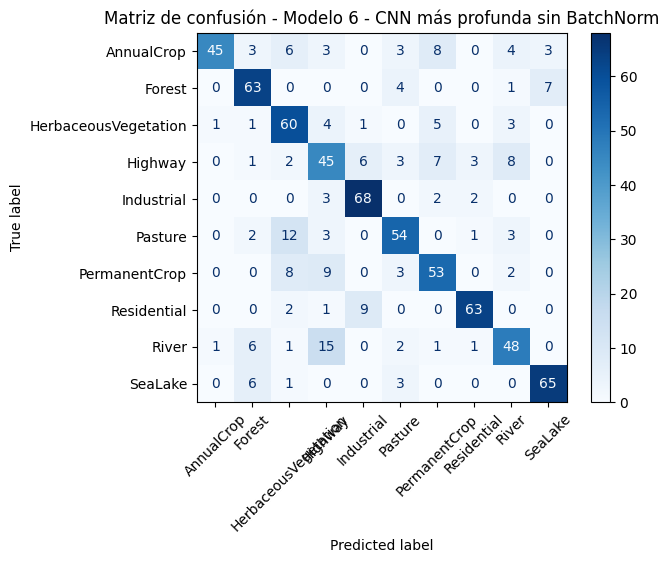

In [46]:
test_gen_nuevo.reset()

predicciones_bloque2 = mejor_modelo_bloque2.predict(test_gen_nuevo)
y_pred_bloque2 = np.argmax(predicciones_bloque2, axis=1)
y_true_bloque2 = test_gen_nuevo.classes

nombres_clases_bloque2 = list(test_gen_nuevo.class_indices.keys())

cm_bloque2 = confusion_matrix(y_true_bloque2, y_pred_bloque2)

plt.figure(figsize=(10, 10))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_bloque2,
    display_labels=nombres_clases_bloque2
)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Matriz de confusión - {mejor_modelo_bloque2_nombre}")
plt.show()

In [47]:
reporte_bloque2 = classification_report(
    y_true_bloque2,
    y_pred_bloque2,
    target_names=nombres_clases_bloque2,
    output_dict=True
)

df_reporte_bloque2 = pd.DataFrame(reporte_bloque2).transpose()

df_reporte_bloque2

,precision,recall,f1-score,support
AnnualCrop,0.957447,0.600000,0.737705,75.000
Forest,0.768293,0.840000,0.802548,75.000
HerbaceousVegetation,0.652174,0.800000,0.718563,75.000
Highway,0.542169,0.600000,0.569620,75.000
Industrial,0.809524,0.906667,0.855346,75.000
Pasture,0.750000,0.720000,0.734694,75.000
PermanentCrop,0.697368,0.706667,0.701987,75.000
Residential,0.900000,0.840000,0.868966,75.000
River,0.695652,0.640000,0.666667,75.000
SeaLake,0.866667,0.866667,0.866667,75.000


In [48]:
print(classification_report(
    y_true_bloque2,
    y_pred_bloque2,
    target_names=nombres_clases_bloque2
))

                      precision    recall  f1-score   support

          AnnualCrop       0.96      0.60      0.74        75
              Forest       0.77      0.84      0.80        75
HerbaceousVegetation       0.65      0.80      0.72        75
             Highway       0.54      0.60      0.57        75
          Industrial       0.81      0.91      0.86        75
             Pasture       0.75      0.72      0.73        75
       PermanentCrop       0.70      0.71      0.70        75
         Residential       0.90      0.84      0.87        75
               River       0.70      0.64      0.67        75
             SeaLake       0.87      0.87      0.87        75

            accuracy                           0.75       750
           macro avg       0.76      0.75      0.75       750
        weighted avg       0.76      0.75      0.75       750



## Conclusiones del segundo bloque experimental

Los resultados del segundo bloque permiten extraer varias conclusiones:

1. **Aumentar la cantidad de datos mejoró el comportamiento general de los modelos**: todos entrenaron más épocas de forma estable y la accuracy de validación máxima subió respecto del primer bloque.
2. **El Modelo 6 (CNN de 3 bloques convolucionales, sin BatchNorm, con Dropout 0.25 y learning rate 0.0005) fue el mejor**, con una accuracy de prueba de 0.7520.
3. El reporte por clase del Modelo 6 muestra que las clases con identidad visual fuerte (**Residential, Industrial, SeaLake, Forest**) se clasifican bien (F1 entre 0.80 y 0.87), mientras que **Highway (F1 0.57), River (0.67) y AnnualCrop (recall 0.60)** siguen siendo las más problemáticas, por compartir rasgos visuales con otras clases (trazados lineales, tonos de vegetación).
4. La brecha que persiste entre entrenamiento y validación indica que el modelo todavía **sobreajusta moderadamente**: memoriza parte de los ejemplos en lugar de generalizar.

Estas observaciones motivan el siguiente paso: atacar el sobreajuste **aumentando la variedad de los datos sin agregar más imágenes**, es decir, mediante **data augmentation**.

# Tercer bloque experimental: data augmentation y refinamiento de la arquitectura

## ¿Por qué se decide probar data augmentation?

Antes de incorporar data augmentation, corresponde justificar **por qué tiene sentido hacerlo en este problema**:

1. **Hay signos de sobreajuste.** En los mejores modelos (4, 5 y 6) la accuracy de entrenamiento supera de forma sostenida a la de validación. El modelo memoriza parte de los ejemplos de entrenamiento en vez de aprender patrones generales. Data augmentation ataca directamente este problema: al transformar aleatoriamente las imágenes en cada época, el modelo nunca ve exactamente la misma imagen dos veces, lo que dificulta la memorización.

2. **La muestra es chica en relación al problema.** Se entrena con 3.500 imágenes (500 por clase) de un dataset de 27.000. Data augmentation permite **aumentar artificialmente la variedad** de los datos sin necesidad de cargar más imágenes ni aumentar el tiempo de carga.

3. **Las imágenes satelitales son especialmente aptas para augmentation.** A diferencia de una fotografía común, una imagen satelital se toma desde una perspectiva cenital y **no tiene una orientación "correcta"**: un bosque sigue siendo un bosque si se lo rota o se lo espeja vertical u horizontalmente. Esto hace que transformaciones geométricas que en otros datasets serían riesgosas (por ejemplo, el flip vertical en fotos de personas) acá sean **semánticamente válidas** y generen ejemplos realistas.

### Transformaciones elegidas y su justificación

| Transformación | Valor | Justificación |
|---|---|---|
| `horizontal_flip` | True | Una escena satelital espejada sigue representando la misma clase. |
| `vertical_flip` | True | Igual que el anterior: no existe un "arriba" natural en una vista cenital. |
| `rotation_range` | 20° | Simula distintas orientaciones de captura del satélite. Se usa un valor moderado para limitar los bordes vacíos que genera la rotación. |
| `width/height_shift` | 0.10 | Simula pequeños desplazamientos del encuadre. |
| `zoom_range` | 0.10 | Simula leves variaciones de altura/escala de captura. |
| `fill_mode` | reflect | Rellena los bordes generados por rotaciones y desplazamientos reflejando la propia imagen, lo que produce bordes más realistas que rellenar con negro. |

**Importante:** no se aplican transformaciones de color (brillo, saturación, cambios de canal), porque en este dataset **el color es una característica discriminativa clave**: el verde distingue vegetación, el azul distingue agua, el gris distingue zonas urbanas. Alterar el color podría confundir clases en lugar de ayudar.

### Hipótesis

Data augmentation debería **reducir la brecha entre entrenamiento y validación** y mejorar la accuracy de prueba. Como contrapartida, el entrenamiento será más lento en converger (el modelo ve datos "más difíciles" en cada época), por lo que en este bloque **se aumenta la cantidad de épocas** y se relaja la paciencia del EarlyStopping.

In [49]:
# Generador de entrenamiento con data augmentation
# (validación y prueba NO se aumentan: deben reflejar los datos reales)

datagen_augmentation = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    vertical_flip=True,
    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    fill_mode="reflect"
)

train_gen_aug = datagen_augmentation.flow_from_dataframe(
    train_df_nuevo,
    x_col="filepath",
    y_col="clase",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

print("Generador con data augmentation creado.")
print("Imágenes de entrenamiento:", train_gen_aug.samples)

Found 3500 validated image filenames belonging to 10 classes.
Generador con data augmentation creado.
Imágenes de entrenamiento: 3500


### Visualización del efecto de data augmentation

Antes de entrenar, se visualiza una misma imagen transformada varias veces. Esto permite verificar que las transformaciones generan ejemplos **realistas y reconocibles**: si las imágenes aumentadas se vieran distorsionadas o irreconocibles, el augmentation estaría mal calibrado y perjudicaría el entrenamiento.

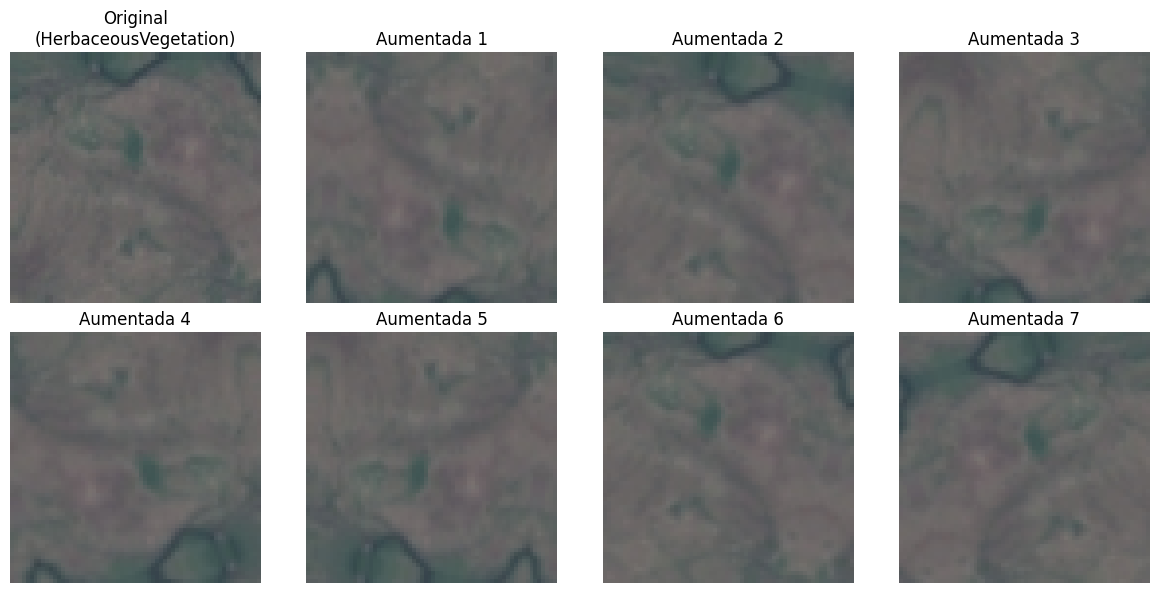

In [50]:
# Visualizar una misma imagen con distintas transformaciones aleatorias

from tensorflow.keras.preprocessing.image import load_img, img_to_array

ejemplo_path = train_df_nuevo.iloc[0]["filepath"]
ejemplo_clase = train_df_nuevo.iloc[0]["clase"]

img = load_img(ejemplo_path, target_size=IMG_SIZE)
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

plt.figure(figsize=(12, 6))

plt.subplot(2, 4, 1)
plt.imshow(img_array[0].astype("uint8"))
plt.title(f"Original\n({ejemplo_clase})")
plt.axis("off")

iterador_aug = datagen_augmentation.flow(img_array, batch_size=1, seed=SEED)

for i in range(7):
    imagen_aug = next(iterador_aug)[0]
    plt.subplot(2, 4, i + 2)
    plt.imshow(imagen_aug)
    plt.title(f"Aumentada {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Las imágenes aumentadas conservan la identidad visual de la clase: las rotaciones, espejados y desplazamientos producen variantes plausibles de la misma escena. Esto confirma que la configuración elegida es adecuada para entrenar.

## Configuración de entrenamiento del tercer bloque

Como el augmentation hace que cada época sea "distinta", el modelo necesita **más épocas para converger**. Se configura:

- `EPOCHS_BLOQUE3 = 30`: techo más alto de épocas.
- `EarlyStopping` con `patience=6`: más tolerancia a épocas sin mejora, porque con augmentation las curvas de validación oscilan más.
- `restore_best_weights=True`: al finalizar, el modelo queda con los pesos de la mejor época de validación.

In [51]:
EPOCHS_BLOQUE3 = 30

def crear_callbacks_bloque3():
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True
        )
    ]

## Modelo 7: mejor arquitectura del bloque 2 + data augmentation

**¿Por qué se crea este modelo?**

El Modelo 7 utiliza **exactamente la misma arquitectura que el Modelo 6** (el mejor hasta ahora), cambiando únicamente el generador de entrenamiento: ahora recibe imágenes con data augmentation.

La decisión metodológica es deliberada: **modificar una sola variable por vez**. Si se cambiara la arquitectura y el preprocesamiento al mismo tiempo, no sería posible saber a qué cambio atribuir la diferencia de resultados. Comparando Modelo 6 vs. Modelo 7 se aísla el efecto del augmentation sobre la misma red y los mismos datos de validación y prueba.

**Hipótesis:** el augmentation debería reducir el sobreajuste (curvas de entrenamiento y validación más cercanas) y mejorar la accuracy de prueba respecto del 0.7520 del Modelo 6.

In [52]:
def crear_modelo_7():
    model = models.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.25),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

modelo_7 = crear_modelo_7()
modelo_7.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 38s 321ms/step - accuracy: 0.2440 - loss: 1.9423 - val_accuracy: 0.3760 - val_loss: 1.6491
Epoch 2/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 35s 320ms/step - accuracy: 0.3957 - loss: 1.5586 - val_accuracy: 0.5320 - val_loss: 1.3379
Epoch 3/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 35s 321ms/step - accuracy: 0.4580 - loss: 1.3826 - val_accuracy: 0.5040 - val_loss: 1.3577
Epoch 4/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 34s 313ms/step - accuracy: 0.5180 - loss: 1.3049 - val_accuracy: 0.5600 - val_loss: 1.1911
Epoch 5/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 35s 322ms/step - accuracy: 0.5151 - loss: 1.3066 - val_accuracy: 0.5893 - val_loss: 1.1304
Epoch 6/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 35s 322ms/step - accuracy: 0.5563 - loss: 1.2021 - val_accuracy: 0.6107 - val_loss: 1.1138
Epoch 7/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 34s 310ms/step - accuracy: 0.5657 - loss: 1.1651 - val_accuracy: 0.5773 - val_loss: 1.1673
Epoch 8/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 35s 317ms/step - accuracy: 0.6034 - loss: 1

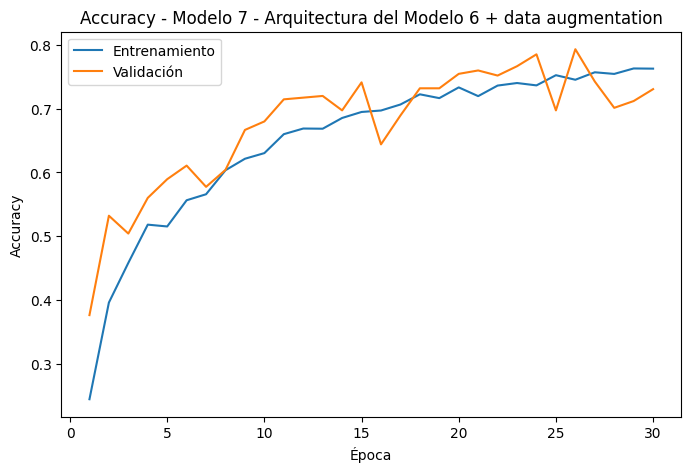

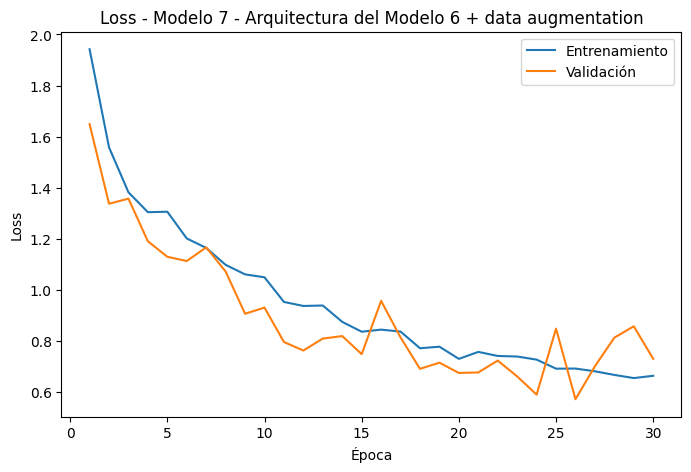

In [53]:
history_7 = modelo_7.fit(
    train_gen_aug,
    validation_data=val_gen_nuevo,
    epochs=EPOCHS_BLOQUE3,
    callbacks=crear_callbacks_bloque3()
)

graficar_historial(history_7, "Modelo 7 - Arquitectura del Modelo 6 + data augmentation")

### Conclusión del Modelo 7

El Modelo 7 alcanzó una **accuracy de prueba de 0.7827**, superando al Modelo 6 (0.7520) con exactamente la misma arquitectura. Como la única variable modificada fue el data augmentation, la mejora de **+3 puntos** es atribuible directamente a esta técnica.

Observaciones sobre las curvas:

- **La brecha entre entrenamiento y validación se invirtió**: la accuracy de validación (máximo 0.7933) superó de forma sostenida a la de entrenamiento (máximo 0.7631). Esto es un comportamiento esperado y saludable con augmentation: el modelo entrena sobre imágenes transformadas ("más difíciles") y se valida sobre imágenes originales, lo que confirma que **el sobreajuste fue eliminado**.
- La convergencia fue más lenta que en el Modelo 6: el modelo siguió mejorando hasta la época 26 y utilizó las 30 épocas disponibles, lo que confirma la hipótesis de que el augmentation requiere más tiempo de entrenamiento.
- Las curvas de validación muestran oscilaciones (por ejemplo, caídas en las épocas 16 y 25), producto de la aleatoriedad de las transformaciones, pero la tendencia general es claramente ascendente.

Conclusión: **el data augmentation funcionó**, validando la hipótesis planteada. El siguiente paso es aprovechar este efecto regularizador para aumentar la capacidad de la red.

## Modelo 8: CNN más profunda con bloques convolucionales dobles + data augmentation

**¿Por qué se crea este modelo?**

Si el augmentation funciona como regularizador, abre la puerta a **aumentar la capacidad del modelo** sin que el sobreajuste se dispare. El Modelo 8 adopta un diseño inspirado en la familia **VGG**, donde cada bloque tiene **dos convoluciones consecutivas** antes del pooling:

- Dos convoluciones 3×3 seguidas equivalen a un campo receptivo de 5×5, pero con **menos parámetros y más no linealidades**, lo que permite aprender patrones más ricos de forma más eficiente.
- Se mantiene la progresión de filtros 32 → 64 → 128, que sigue la lógica estándar: a medida que la resolución espacial se reduce con el pooling, se aumenta la cantidad de filtros para representar características más abstractas.
- Se agrega un **Dropout suave (0.25) también entre bloques convolucionales**, además del de la cabeza densa, porque la red ahora tiene más parámetros que proteger contra el sobreajuste.

**Hipótesis:** con el augmentation controlando el sobreajuste, la mayor capacidad debería traducirse en mejor accuracy. El riesgo es que, si la red resulta demasiado grande para 3.500 imágenes (aun aumentadas), el entrenamiento sea más lento o inestable.

In [54]:
def crear_modelo_8():
    model = models.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.40),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

modelo_8 = crear_modelo_8()
modelo_8.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,337,002 (5.10 MB)

 Trainable params: 1,337,002 (5.10 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 99s 866ms/step - accuracy: 0.2014 - loss: 2.0276 - val_accuracy: 0.2600 - val_loss: 1.8267
Epoch 2/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 94s 854ms/step - accuracy: 0.2629 - loss: 1.8373 - val_accuracy: 0.3480 - val_loss: 1.6120
Epoch 3/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 96s 873ms/step - accuracy: 0.3846 - loss: 1.5841 - val_accuracy: 0.4787 - val_loss: 1.2899
Epoch 4/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 96s 870ms/step - accuracy: 0.4866 - loss: 1.3511 - val_accuracy: 0.5667 - val_loss: 1.1449
Epoch 5/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 97s 882ms/step - accuracy: 0.5403 - loss: 1.2468 - val_accuracy: 0.6280 - val_loss: 1.0005
Epoch 6/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 97s 882ms/step - accuracy: 0.5754 - loss: 1.1426 - val_accuracy: 0.5680 - val_loss: 1.1717
Epoch 7/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 141s 875ms/step - accuracy: 0.5840 - loss: 1.1380 - val_accuracy: 0.6200 - val_loss: 0.9789
Epoch 8/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 95s 864ms/step - accuracy: 0.6103 - loss: 

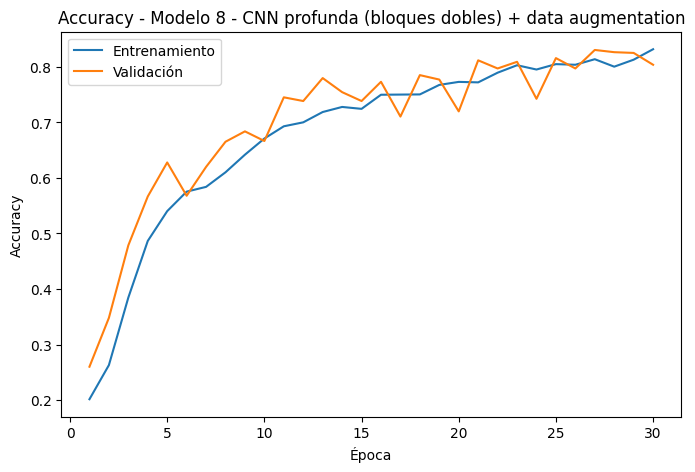

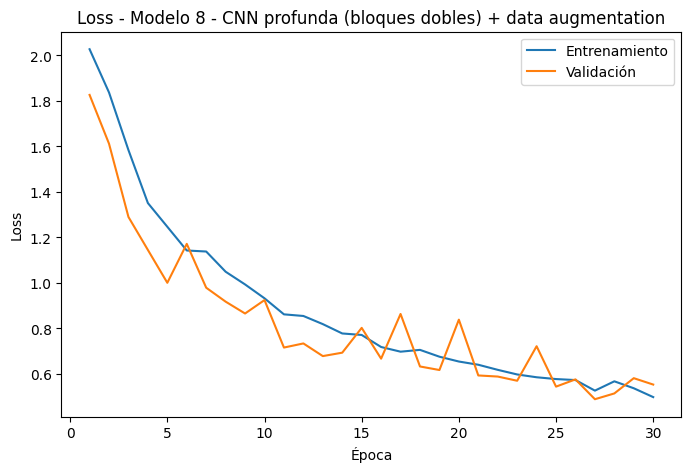

In [55]:
history_8 = modelo_8.fit(
    train_gen_aug,
    validation_data=val_gen_nuevo,
    epochs=EPOCHS_BLOQUE3,
    callbacks=crear_callbacks_bloque3()
)

graficar_historial(history_8, "Modelo 8 - CNN profunda (bloques dobles) + data augmentation")

### Conclusión del Modelo 8

El Modelo 8 fue el **mejor de todo el trabajo**: **accuracy de prueba de 0.8187** y mejor accuracy de validación de 0.8307.

Observaciones:

- La hipótesis se confirmó: con el augmentation actuando como regularizador, la mayor capacidad de los bloques convolucionales dobles se tradujo en mejor rendimiento (+3.6 puntos sobre el Modelo 7, que tenía la misma configuración de datos pero menor profundidad).
- Como se esperaba, la red más grande tardó más en despegar (época 1: 0.20 de accuracy contra 0.24 del Modelo 7), pero a partir de la época 11 superó consistentemente al Modelo 7.
- Las curvas de entrenamiento y validación avanzaron juntas durante todo el entrenamiento (entrenamiento final 0.83, mejor validación 0.83): **no hay signos de sobreajuste** a pesar de ser la red con más parámetros del trabajo.
- La loss de prueba (0.5550) es la menor de todos los experimentos, lo que indica predicciones mejor calibradas.

Conclusión: la combinación profundidad + augmentation fue la más efectiva. Este modelo se perfila como candidato a modelo final.

## Modelo 9: Modelo 8 + BatchNormalization + reducción dinámica del learning rate

**¿Por qué se crea este modelo?**

Este experimento **reintenta BatchNormalization**, que falló en el Modelo 3. La decisión no es arbitraria: las condiciones que explicaban aquella falla cambiaron.

- En el Modelo 3, BatchNorm se aplicó con una muestra chica (300 imágenes por clase) y un entrenamiento muy corto (3 épocas), sin tiempo para que sus estadísticas internas (media y varianza acumuladas) se estabilizaran.
- Ahora hay **más datos (500 por clase)**, **augmentation** (que aporta variedad estadística a cada lote) y un **techo de 30 épocas con mayor paciencia**, condiciones bajo las cuales BatchNorm suele funcionar y acelerar la convergencia.
- Se usa el orden canónico **Conv → BatchNorm → ReLU**, que normaliza las activaciones antes de la no linealidad.

Además se incorpora **ReduceLROnPlateau**: si la loss de validación se estanca, el learning rate se reduce automáticamente a la mitad. Esto permite arrancar con un learning rate más alto (0.001, que acelera el comienzo) y refinarlo cuando el modelo se acerca a su mejor punto, en lugar de fijar un único valor para todo el entrenamiento.

**Hipótesis:** la combinación BatchNorm + augmentation + reducción dinámica del learning rate debería lograr un entrenamiento más rápido y estable que el del Modelo 8, y posiblemente el mejor resultado del trabajo. Si BatchNorm vuelve a degradar la validación, se confirmará que no es adecuada para esta escala de datos.

In [56]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

def crear_modelo_9():
    model = models.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(128, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.40),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

def crear_callbacks_modelo9():
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-5,
            verbose=1
        )
    ]

modelo_9 = crear_modelo_9()
modelo_9.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 8, 8, 128)      │             

 Total params: 1,338,794 (5.11 MB)

 Trainable params: 1,337,898 (5.10 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.2980 - loss: 2.2065 - val_accuracy: 0.1000 - val_loss: 2.4636 - learning_rate: 0.0010
Epoch 2/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.3911 - loss: 1.6541 - val_accuracy: 0.1067 - val_loss: 2.4457 - learning_rate: 0.0010
Epoch 3/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.4297 - loss: 1.5399 - val_accuracy: 0.1973 - val_loss: 2.2595 - learning_rate: 0.0010
Epoch 4/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.4486 - loss: 1.5035 - val_accuracy: 0.4013 - val_loss: 1.7855 - learning_rate: 0.0010
Epoch 5/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.4637 - loss: 1.4607 - val_accuracy: 0.3813 - val_loss: 1.7580 - learning_rate: 0.0010
Epoch 6/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - accuracy: 0.4906 - loss: 1.3832 - val_accuracy: 0.5707 - val_loss: 1.2647 - learning_rate: 0.0010
Epoch 7/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.4986 - loss: 1.

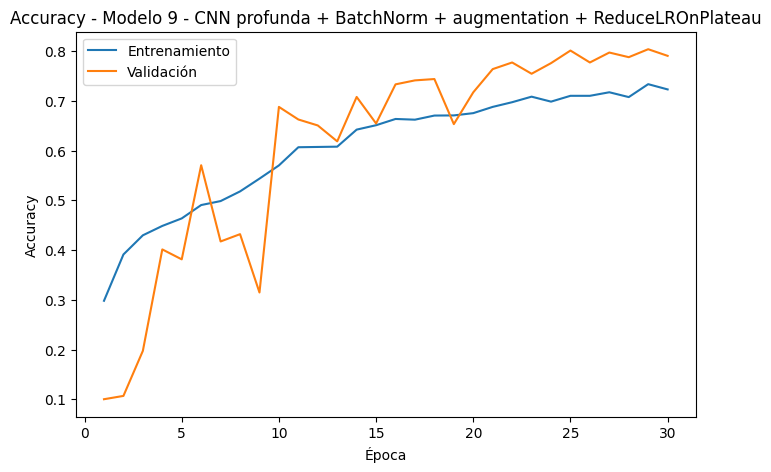

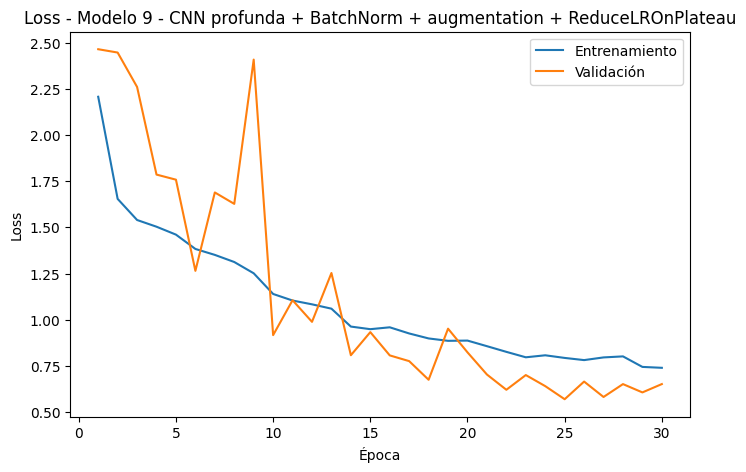

In [57]:
history_9 = modelo_9.fit(
    train_gen_aug,
    validation_data=val_gen_nuevo,
    epochs=EPOCHS_BLOQUE3,
    callbacks=crear_callbacks_modelo9()
)

graficar_historial(history_9, "Modelo 9 - CNN profunda + BatchNorm + augmentation + ReduceLROnPlateau")

### Conclusión del Modelo 9

El Modelo 9 alcanzó una **accuracy de prueba de 0.8067**: muy buen resultado, aunque no superó al Modelo 8 (0.8187).

Observaciones:

- **BatchNormalization sí funcionó esta vez**, a diferencia del Modelo 3. Las primeras épocas repitieron el patrón problemático (validación en 0.10–0.20 mientras el entrenamiento avanzaba), pero a partir de la época 4 las estadísticas internas de BatchNorm se estabilizaron y la validación se recuperó hasta alcanzar 0.8040. Esto confirma la hipótesis: la falla del Modelo 3 se debía a las condiciones (pocos datos, solo 3 épocas), no a la técnica en sí.
- **ReduceLROnPlateau actuó cuatro veces** (épocas 9, 13, 21 y 28, reduciendo el learning rate de 0.001 hasta 0.0000625). Después de cada reducción la loss de validación retomó la mejora, en especial tras la de la época 9 (val_loss bajó de 2.40 a 0.92 en la época siguiente).
- A pesar del entrenamiento más estable en su tramo final, no superó al Modelo 8: el costo de las épocas iniciales "perdidas" en estabilizar BatchNorm pesó dentro del límite de 30 épocas. Con más épocas disponibles, posiblemente cerraría la diferencia.

Conclusión: BatchNorm es viable en estas condiciones pero no aportó ventaja neta frente al Modelo 8, que logra mejor resultado con una arquitectura más simple.

## Comparación de resultados del tercer bloque

Los Modelos 7, 8 y 9 se evalúan sobre el mismo conjunto de prueba que los Modelos 4, 5 y 6 (la partición de 500 imágenes por clase), por lo que la comparación entre los bloques 2 y 3 es directa y justa.

In [58]:
resultados_bloque3 = []

resultados_bloque3.append(
    obtener_metricas("Modelo 7 - Arquitectura M6 + augmentation", modelo_7, history_7, test_gen_nuevo)
)

resultados_bloque3.append(
    obtener_metricas("Modelo 8 - CNN profunda + augmentation", modelo_8, history_8, test_gen_nuevo)
)

resultados_bloque3.append(
    obtener_metricas("Modelo 9 - CNN profunda + BatchNorm + aug + ReduceLR", modelo_9, history_9, test_gen_nuevo)
)

df_resultados_bloque3 = pd.DataFrame(resultados_bloque3)

df_resultados_bloque3.sort_values("Test accuracy", ascending=False)

,Modelo,Mejor val_accuracy,Menor val_loss,Test accuracy,Test loss,Épocas entrenadas
1,Modelo 8 - CNN profunda + augmentation,0.830667,0.488556,0.818667,0.555000,30
2,Modelo 9 - CNN profunda + BatchNorm + aug + Re...,0.804000,0.570366,0.806667,0.581682,30
0,Modelo 7 - Arquitectura M6 + augmentation,0.793333,0.573265,0.782667,0.647786,30


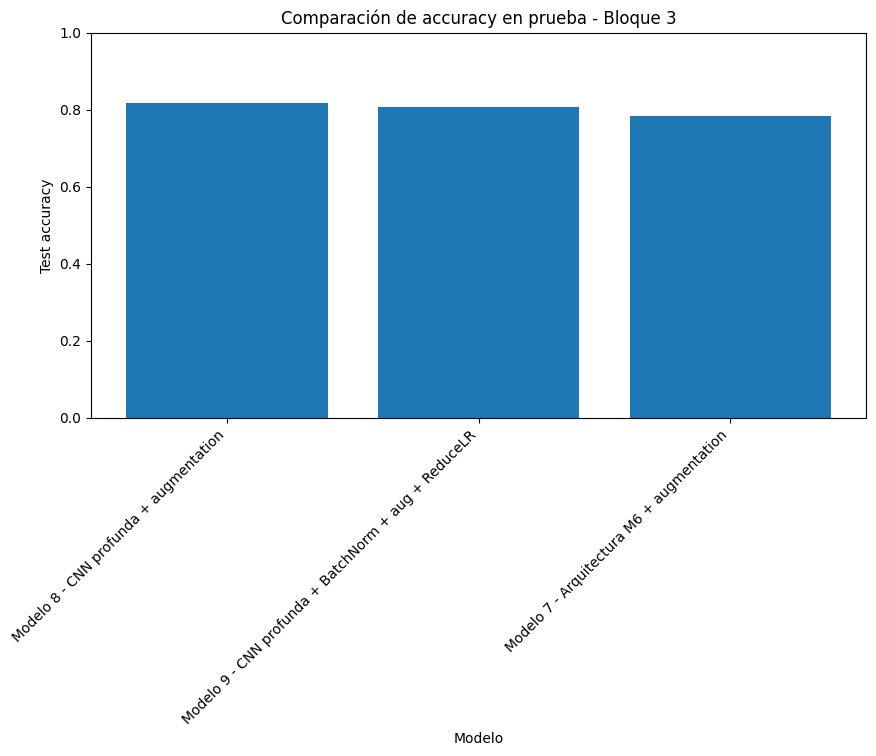

In [59]:
df_bloque3_ordenado = df_resultados_bloque3.sort_values("Test accuracy", ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(df_bloque3_ordenado["Modelo"], df_bloque3_ordenado["Test accuracy"])
plt.title("Comparación de accuracy en prueba - Bloque 3")
plt.xlabel("Modelo")
plt.ylabel("Test accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.show()

## Comparación general de todos los experimentos

Se consolidan los resultados de los tres bloques experimentales en una única tabla y gráfico.

**Aclaración metodológica:** los modelos del bloque 1 se evaluaron sobre un conjunto de prueba distinto (450 imágenes, de la muestra de 300 por clase), por lo que su comparación con los bloques 2 y 3 es orientativa. Los modelos de los bloques 2 y 3 comparten exactamente el mismo conjunto de prueba (750 imágenes) y son directamente comparables.

In [60]:
df_resultados_bloque3["Bloque"] = "Bloque 3 - 500 imágenes + augmentation"

df_comparacion_final = pd.concat(
    [df_comparacion_total, df_resultados_bloque3],
    ignore_index=True
)

df_comparacion_final.sort_values("Test accuracy", ascending=False)

,Modelo,Mejor val_accuracy,Menor val_loss,Test accuracy,Test loss,Épocas entrenadas,Bloque
7,Modelo 8 - CNN profunda + augmentation,0.830667,0.488556,0.818667,0.555000,30,Bloque 3 - 500 imágenes + augmentation
8,Modelo 9 - CNN profunda + BatchNorm + aug + Re...,0.804000,0.570366,0.806667,0.581682,30,Bloque 3 - 500 imágenes + augmentation
6,Modelo 7 - Arquitectura M6 + augmentation,0.793333,0.573265,0.782667,0.647786,30,Bloque 3 - 500 imágenes + augmentation
5,Modelo 6 - CNN más profunda sin BatchNorm,0.768000,0.689881,0.752000,0.746740,12,Bloque 2 - 500 imágenes por clase
4,Modelo 5 - CNN + Dropout suave + LR menor,0.742667,0.762794,0.725333,0.798244,12,Bloque 2 - 500 imágenes por clase
0,Modelo 1 - CNN simple,0.662222,0.966623,0.706667,0.870919,8,Bloque 1 - 300 imágenes por clase
3,Modelo 4 - CNN base con 500 imágenes,0.722667,0.801595,0.690667,0.867768,12,Bloque 2 - 500 imágenes por clase
1,Modelo 2 - CNN + Dropout,0.520000,1.525639,0.282222,1.883321,3,Bloque 1 - 300 imágenes por clase
2,Modelo 3 - BatchNorm + Dropout,0.142222,2.427975,0.142222,2.426757,3,Bloque 1 - 300 imágenes por clase


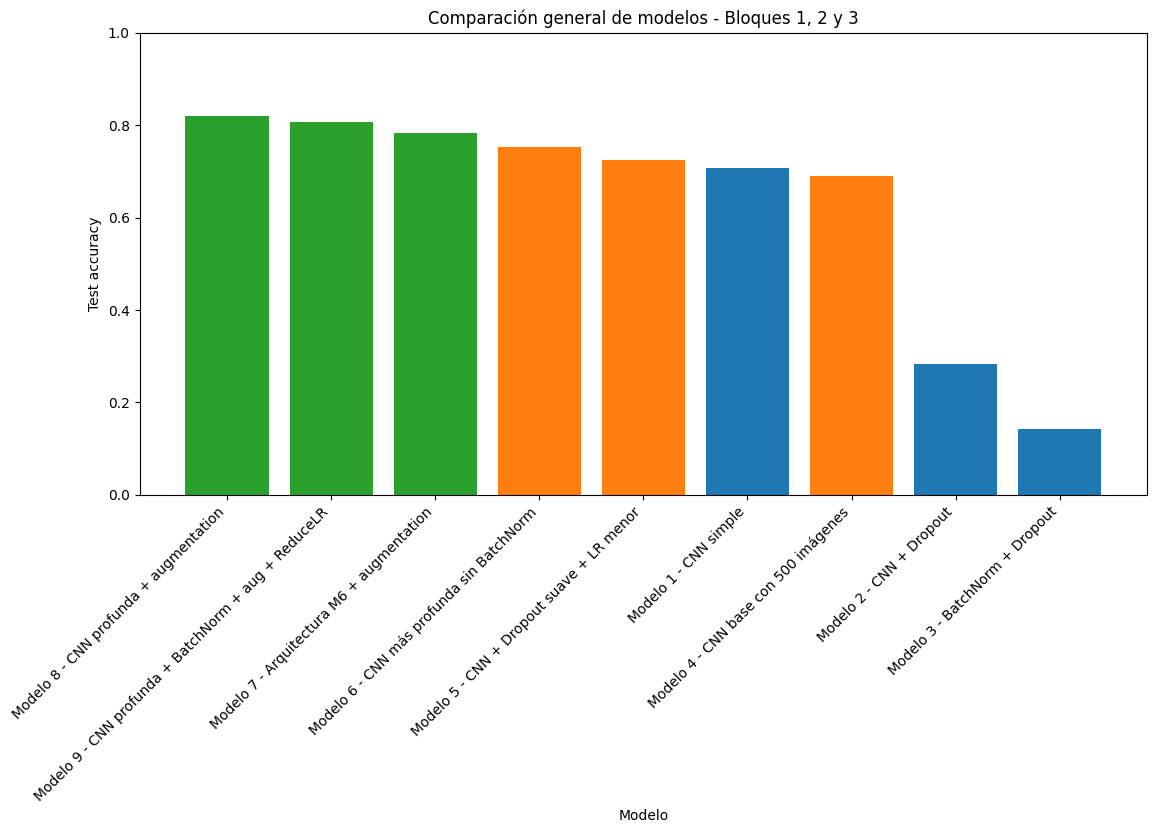

In [61]:
df_final_ordenado = df_comparacion_final.sort_values("Test accuracy", ascending=False)

plt.figure(figsize=(13, 6))
colores = ["tab:green" if "Bloque 3" in b else ("tab:orange" if "Bloque 2" in b else "tab:blue")
           for b in df_final_ordenado["Bloque"]]
plt.bar(df_final_ordenado["Modelo"], df_final_ordenado["Test accuracy"], color=colores)
plt.title("Comparación general de modelos - Bloques 1, 2 y 3")
plt.xlabel("Modelo")
plt.ylabel("Test accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.show()

# Selección del modelo final

## Criterio de selección

El modelo final se elige entre los candidatos entrenados sobre la partición de 500 imágenes por clase (Modelos 4 a 9), que comparten el mismo conjunto de prueba. El criterio principal es la **accuracy sobre el conjunto de prueba**, porque mide el rendimiento sobre datos que el modelo nunca vio, ni siquiera indirectamente a través del EarlyStopping (que monitorea validación).

Como criterios secundarios, ante resultados similares, se prioriza:

1. **Menor brecha entre entrenamiento y validación** (mejor generalización).
2. **Menor loss de prueba** (predicciones más confiadas y calibradas).
3. **Menor complejidad** (a igualdad de rendimiento, el modelo más simple es preferible).

In [62]:
candidatos = df_comparacion_final[
    df_comparacion_final["Bloque"].str.contains("Bloque 2|Bloque 3")
]

mejor_fila_final = candidatos.sort_values("Test accuracy", ascending=False).iloc[0]
nombre_modelo_final = mejor_fila_final["Modelo"]

print("Modelo final seleccionado:")
print(nombre_modelo_final)
print(f"Test accuracy: {mejor_fila_final['Test accuracy']:.4f}")
print(f"Test loss: {mejor_fila_final['Test loss']:.4f}")

mapa_modelos = {
    "Modelo 4": modelo_4,
    "Modelo 5": modelo_5,
    "Modelo 6": modelo_6,
    "Modelo 7": modelo_7,
    "Modelo 8": modelo_8,
    "Modelo 9": modelo_9,
}

modelo_final = None
for prefijo, m in mapa_modelos.items():
    if nombre_modelo_final.startswith(prefijo):
        modelo_final = m
        break

Modelo final seleccionado:
Modelo 8 - CNN profunda + augmentation
Test accuracy: 0.8187
Test loss: 0.5550


## Evaluación detallada del modelo final

Se analiza el modelo final con la matriz de confusión y las métricas por clase (precision, recall y F1-score) sobre el conjunto de prueba, para identificar en qué clases acierta y en cuáles se confunde.

24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 235ms/step


<Figure size 1000x1000 with 0 Axes>

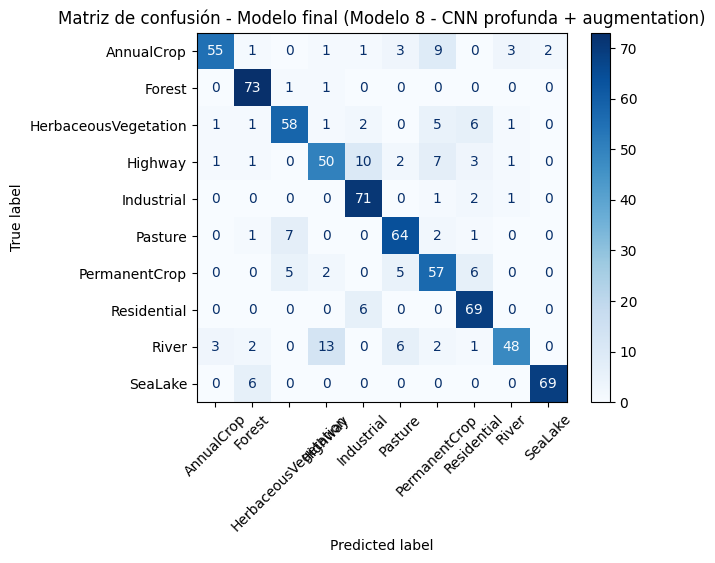

In [63]:
test_gen_nuevo.reset()

predicciones_final = modelo_final.predict(test_gen_nuevo)
y_pred_final = np.argmax(predicciones_final, axis=1)
y_true_final = test_gen_nuevo.classes

nombres_clases_final = list(test_gen_nuevo.class_indices.keys())

cm_final = confusion_matrix(y_true_final, y_pred_final)

plt.figure(figsize=(10, 10))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=nombres_clases_final
)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Matriz de confusión - Modelo final ({nombre_modelo_final})")
plt.show()

In [64]:
print(classification_report(
    y_true_final,
    y_pred_final,
    target_names=nombres_clases_final
))

                      precision    recall  f1-score   support

          AnnualCrop       0.92      0.73      0.81        75
              Forest       0.86      0.97      0.91        75
HerbaceousVegetation       0.82      0.77      0.79        75
             Highway       0.74      0.67      0.70        75
          Industrial       0.79      0.95      0.86        75
             Pasture       0.80      0.85      0.83        75
       PermanentCrop       0.69      0.76      0.72        75
         Residential       0.78      0.92      0.85        75
               River       0.89      0.64      0.74        75
             SeaLake       0.97      0.92      0.95        75

            accuracy                           0.82       750
           macro avg       0.82      0.82      0.82       750
        weighted avg       0.82      0.82      0.82       750



### Visualización de predicciones del modelo final

Se muestran ejemplos del conjunto de prueba con su etiqueta real y la predicción del modelo, para inspeccionar visualmente aciertos y errores.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step


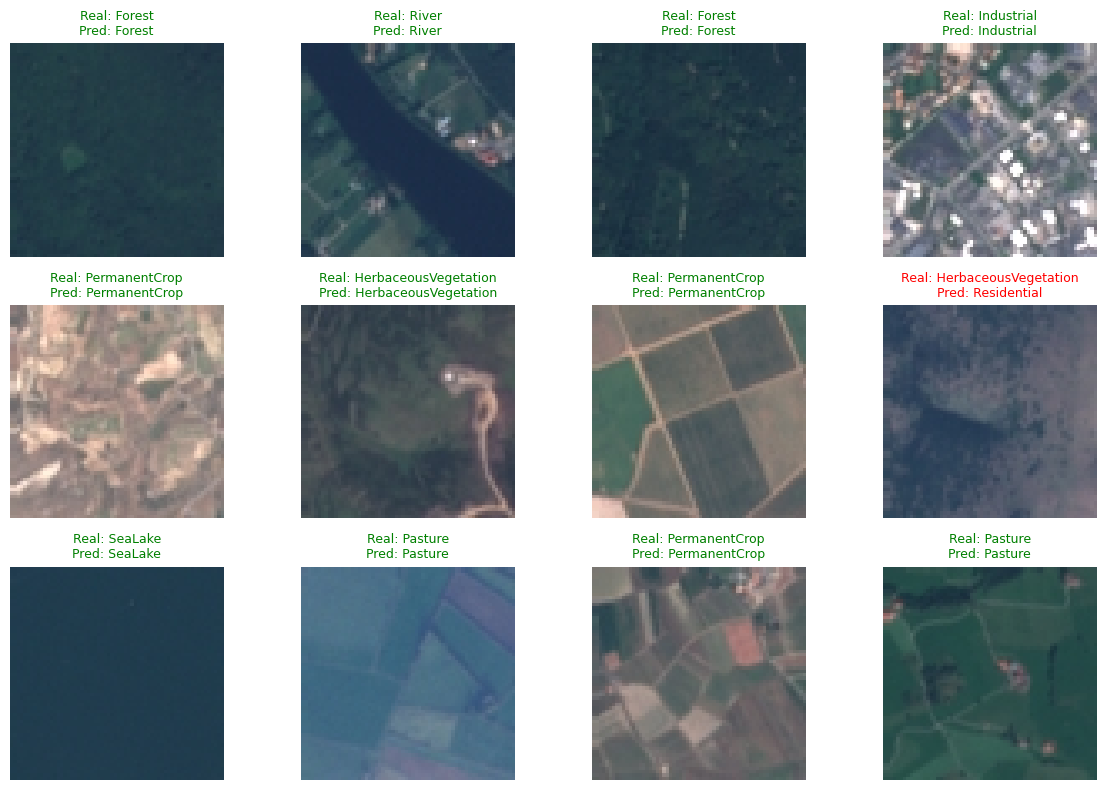

In [65]:
test_gen_nuevo.reset()

imagenes_test_final, etiquetas_test_final = next(test_gen_nuevo)
preds_final = modelo_final.predict(imagenes_test_final)

idx_to_class_final = {v: k for k, v in test_gen_nuevo.class_indices.items()}

plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(imagenes_test_final[i])

    real_idx = np.argmax(etiquetas_test_final[i])
    pred_idx = np.argmax(preds_final[i])

    real = idx_to_class_final[real_idx]
    pred = idx_to_class_final[pred_idx]

    color = "green" if real == pred else "red"
    plt.title(f"Real: {real}\nPred: {pred}", color=color, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [66]:
# Análisis de los errores más frecuentes del modelo final

errores = []

for i in range(len(nombres_clases_final)):
    for j in range(len(nombres_clases_final)):
        if i != j and cm_final[i, j] > 0:
            errores.append({
                "Clase real": nombres_clases_final[i],
                "Clase predicha": nombres_clases_final[j],
                "Cantidad": cm_final[i, j]
            })

df_errores = pd.DataFrame(errores).sort_values("Cantidad", ascending=False)

print("Confusiones más frecuentes del modelo final:")
df_errores.head(10)

Confusiones más frecuentes del modelo final:


,Clase real,Clase predicha,Cantidad
37,River,Highway,13
18,Highway,Industrial,10
4,AnnualCrop,PermanentCrop,9
27,Pasture,HerbaceousVegetation,7
20,Highway,PermanentCrop,7
33,PermanentCrop,Residential,6
38,River,Pasture,6
14,HerbaceousVegetation,Residential,6
34,Residential,Industrial,6
41,SeaLake,Forest,6


# Cuarto bloque experimental: refinamiento del data augmentation

El Bloque 3 demostró que el data augmentation fue el factor de mejora más importante del trabajo (Modelo 7: +3 puntos con la misma arquitectura; Modelo 8: 0.8187 de accuracy de prueba). En este bloque se busca **refinar esa técnica** manteniendo todo lo demás constante.

## Refinamiento propuesto: rotaciones de 90° exactos

El augmentation del Bloque 3 usaba `rotation_range=20` (rotaciones aleatorias de hasta ±20°). Este tipo de rotación tiene un costo oculto: al rotar una imagen cuadrada en un ángulo arbitrario, **quedan bordes vacíos en las esquinas** que deben rellenarse artificialmente (en nuestro caso con `fill_mode="reflect"`). Esos píxeles de relleno no existen en los datos reales y agregan un patrón artificial que el modelo podría aprender.

La alternativa propuesta son **rotaciones de 90° exactos** (0°, 90°, 180° o 270°, elegidas al azar): en una imagen cuadrada, una rotación de 90° **no genera ningún borde vacío** — la imagen resultante es un dato perfectamente válido. Además, este refinamiento **amplía** el rango de variación: en lugar de orientaciones dentro de un cono de ±20°, el modelo ahora ve la escena en las cuatro orientaciones posibles, todas igualmente realistas en imágenes satelitales cenitales, donde no existe un "arriba" natural.

Se conservan los flips horizontal y vertical y el zoom suave del Bloque 3, y se elimina el desplazamiento (`shift`), que también generaba bordes de relleno.

## Diseño del experimento

Se mantiene **la misma muestra de 500 imágenes por clase y la misma partición 70/15/15** de los bloques 2 y 3 (garantizado por el uso de la misma semilla aleatoria). De este modo, el Modelo 10 difiere del Modelo 8 **en una sola variable** (el esquema de augmentation), y ambos se evalúan sobre exactamente el mismo conjunto de prueba, lo que permite una comparación directa.

## Verificación del preprocesamiento

Aprovechando el inicio del bloque, se verifica formalmente una decisión de preprocesamiento sostenida desde el comienzo: **no se redimensionan las imágenes**, porque el dataset EuroSAT ya provee todas las imágenes en 64×64 píxeles RGB. La celda siguiente lo comprueba sobre una muestra, fundamentando que el `target_size=(64, 64)` de los generadores no altera los datos. La única transformación de valores aplicada es el **reescalado 1/255**, que lleva los píxeles del rango [0, 255] al rango [0, 1]: las redes neuronales entrenan de forma más estable con entradas pequeñas y acotadas, porque los gradientes quedan en escalas comparables entre capas.

In [67]:
# Verificación del preprocesamiento: tamaño, modo de color y rango de píxeles

from PIL import Image

muestra_paths = df["filepath"].sample(200, random_state=SEED)

tamanios = set()
modos = set()

for path in muestra_paths:
    with Image.open(path) as img:
        tamanios.add(img.size)
        modos.add(img.mode)

print("Tamaños encontrados en la muestra:", tamanios)
print("Modos de color encontrados:", modos)

img_ejemplo = np.array(Image.open(muestra_paths.iloc[0]))
print("Rango de píxeles original:", img_ejemplo.min(), "-", img_ejemplo.max())
print("Rango luego del reescalado 1/255:",
      round(img_ejemplo.min()/255, 3), "-", round(img_ejemplo.max()/255, 3))

Tamaños encontrados en la muestra: {(64, 64)}
Modos de color encontrados: {'RGB'}
Rango de píxeles original: 21 - 79
Rango luego del reescalado 1/255: 0.082 - 0.31


In [68]:
IMAGENES_POR_CLASE_B4 = 500

df_b4 = (
    df.groupby("clase", group_keys=False)
      .apply(lambda x: x.sample(n=min(IMAGENES_POR_CLASE_B4, len(x)), random_state=SEED))
      .reset_index(drop=True)
)

train_df_b4, temp_df_b4 = train_test_split(
    df_b4, test_size=0.30, stratify=df_b4["clase"], random_state=SEED
)
val_df_b4, test_df_b4 = train_test_split(
    temp_df_b4, test_size=0.50, stratify=temp_df_b4["clase"], random_state=SEED
)

print("Total:", len(df_b4))
print("Entrenamiento:", train_df_b4.shape, "| Validación:", val_df_b4.shape, "| Prueba:", test_df_b4.shape)
print("\nDistribución entrenamiento:")
print(train_df_b4["clase"].value_counts().sort_index())

Total: 5000
Entrenamiento: (3500, 2) | Validación: (750, 2) | Prueba: (750, 2)

Distribución entrenamiento:
clase
AnnualCrop              350
Forest                  350
HerbaceousVegetation    350
Highway                 350
Industrial              350
Pasture                 350
PermanentCrop           350
Residential             350
River                   350
SeaLake                 350
Name: count, dtype: int64


/tmp/ipykernel_3162/3964756734.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(IMAGENES_POR_CLASE_B4, len(x)), random_state=SEED))


In [69]:
# Generadores del bloque 4: augmentation refinado con rotaciones de 90° exactos

def rotacion_90_aleatoria(imagen):
    """Rota la imagen 0, 90, 180 o 270 grados al azar, sin generar bordes vacíos."""
    k = np.random.randint(0, 4)
    return np.rot90(imagen, k)

datagen_aug_b4 = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    vertical_flip=True,
    zoom_range=0.10,
    preprocessing_function=rotacion_90_aleatoria
)

train_gen_b4 = datagen_aug_b4.flow_from_dataframe(
    train_df_b4, x_col="filepath", y_col="clase",
    target_size=IMG_SIZE, color_mode="rgb", class_mode="categorical",
    batch_size=BATCH_SIZE, shuffle=True, seed=SEED
)

val_gen_b4 = datagen_simple.flow_from_dataframe(
    val_df_b4, x_col="filepath", y_col="clase",
    target_size=IMG_SIZE, color_mode="rgb", class_mode="categorical",
    batch_size=BATCH_SIZE, shuffle=False
)

test_gen_b4 = datagen_simple.flow_from_dataframe(
    test_df_b4, x_col="filepath", y_col="clase",
    target_size=IMG_SIZE, color_mode="rgb", class_mode="categorical",
    batch_size=BATCH_SIZE, shuffle=False
)

Found 3500 validated image filenames belonging to 10 classes.
Found 750 validated image filenames belonging to 10 classes.
Found 750 validated image filenames belonging to 10 classes.


## Modelo 10: arquitectura del Modelo 8 con augmentation refinado

**¿Por qué se crea este modelo?**

El Modelo 10 reutiliza **exactamente la arquitectura del Modelo 8** (el mejor del trabajo hasta ahora) y los mismos datos. La única modificación es el esquema de data augmentation: rotaciones de 90° exactos en lugar de rotaciones arbitrarias de ±20°, sin desplazamientos.

Se mantiene la metodología de todo el trabajo: **cambiar una sola variable por vez**. Si el rendimiento mejora, la mejora será atribuible al refinamiento del augmentation; si empeora, indicará que las rotaciones arbitrarias y los desplazamientos aportaban una variabilidad útil que las rotaciones exactas no cubren.

**Hipótesis:** al eliminar los píxeles de relleno artificiales y ofrecer las cuatro orientaciones completas de cada escena, el modelo debería igualar o superar la accuracy de prueba de 0.8187 del Modelo 8, con un entrenamiento al menos igual de estable.

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,337,002 (5.10 MB)

 Trainable params: 1,337,002 (5.10 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 97s 840ms/step - accuracy: 0.1860 - loss: 2.0797 - val_accuracy: 0.2787 - val_loss: 1.8081
Epoch 2/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 93s 843ms/step - accuracy: 0.2857 - loss: 1.7918 - val_accuracy: 0.4107 - val_loss: 1.5798
Epoch 3/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 92s 833ms/step - accuracy: 0.3691 - loss: 1.5718 - val_accuracy: 0.4120 - val_loss: 1.3619
Epoch 4/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 93s 842ms/step - accuracy: 0.4766 - loss: 1.3601 - val_accuracy: 0.6067 - val_loss: 1.1313
Epoch 5/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 92s 839ms/step - accuracy: 0.5437 - loss: 1.2578 - val_accuracy: 0.6040 - val_loss: 1.0523
Epoch 6/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 98s 888ms/step - accuracy: 0.5883 - loss: 1.1492 - val_accuracy: 0.5733 - val_loss: 1.1456
Epoch 7/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 140s 872ms/step - accuracy: 0.6071 - loss: 1.0882 - val_accuracy: 0.6720 - val_loss: 0.8875
Epoch 8/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 94s 853ms/step - accuracy: 0.6303 - loss: 

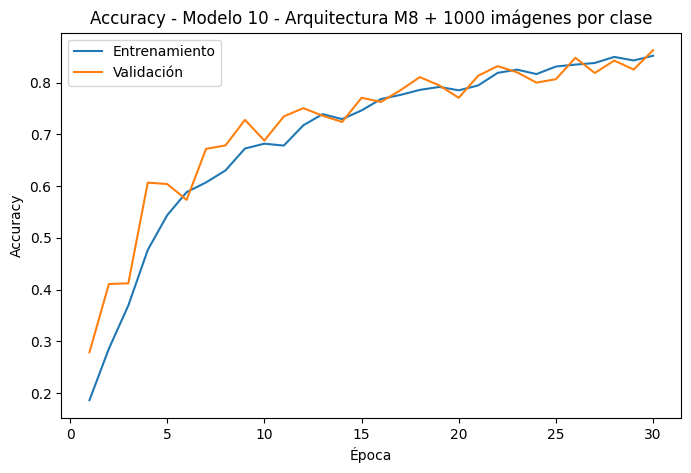

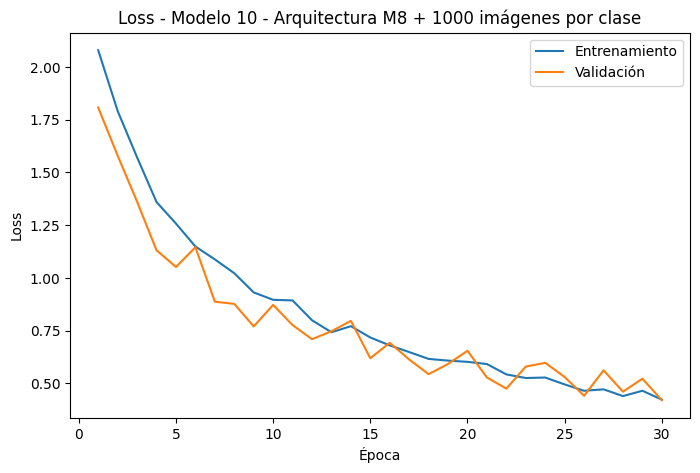

In [70]:
# El Modelo 10 reutiliza la función constructora del Modelo 8 (misma arquitectura)

modelo_10 = crear_modelo_8()
modelo_10.summary()

history_10 = modelo_10.fit(
    train_gen_b4,
    validation_data=val_gen_b4,
    epochs=EPOCHS_BLOQUE3,
    callbacks=crear_callbacks_bloque3()
)

graficar_historial(history_10, "Modelo 10 - Arquitectura M8 + 1000 imágenes por clase")

In [78]:
# Métricas del Modelo 10 y comparación general

resultado_10 = obtener_metricas(
    "Modelo 10 - Arq. M8 + 1000 img/clase", modelo_10, history_10, test_gen_b4
)
resultado_10["Bloque"] = "Bloque 4 - 1000 imágenes + augmentation refinado"

df_comparacion_final = pd.concat(
    [df_comparacion_final, pd.DataFrame([resultado_10])], ignore_index=True
)

df_comparacion_final.sort_values("Test accuracy", ascending=False)

,Modelo,Mejor val_accuracy,Menor val_loss,Test accuracy,Test loss,Épocas entrenadas,Bloque
11,Modelo 10 - Arq. M8,0.862667,0.420378,0.844000,0.458377,30,Bloque 4 - 1000 imágenes + augmentation refinado
12,Modelo 10 - Arq. M8 + 1000 img/clase,0.862667,0.420378,0.844000,0.458377,30,Bloque 4 - 1000 imágenes + augmentation refinado
9,Modelo 10 - Arq. M8 + 1000 img/clase,0.862667,0.420378,0.844000,0.458377,30,Bloque 4 - 1000 imágenes + augmentation refinado
10,Modelo 11 - Config. M10 + entrenamiento extendido,0.826667,0.495313,0.821333,0.534955,25,Bloque 4 - 500 imágenes + augmentation refinado
7,Modelo 8 - CNN profunda + augmentation,0.830667,0.488556,0.818667,0.555000,30,Bloque 3 - 500 imágenes + augmentation
8,Modelo 9 - CNN profunda + BatchNorm + aug + Re...,0.804000,0.570366,0.806667,0.581682,30,Bloque 3 - 500 imágenes + augmentation
6,Modelo 7 - Arquitectura M6 + augmentation,0.793333,0.573265,0.782667,0.647786,30,Bloque 3 - 500 imágenes + augmentation
5,Modelo 6 - CNN más profunda sin BatchNorm,0.768000,0.689881,0.752000,0.746740,12,Bloque 2 - 500 imágenes por clase
4,Modelo 5 - CNN + Dropout suave + LR menor,0.742667,0.762794,0.725333,0.798244,12,Bloque 2 - 500 imágenes por clase
0,Modelo 1 - CNN simple,0.662222,0.966623,0.706667,0.870919,8,Bloque 1 - 300 imágenes por clase


24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 232ms/step


<Figure size 1000x1000 with 0 Axes>

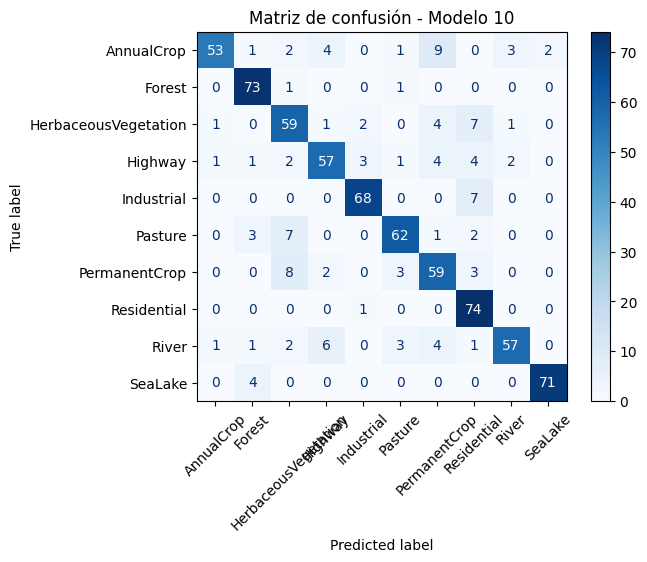

                      precision    recall  f1-score   support

          AnnualCrop       0.95      0.71      0.81        75
              Forest       0.88      0.97      0.92        75
HerbaceousVegetation       0.73      0.79      0.76        75
             Highway       0.81      0.76      0.79        75
          Industrial       0.92      0.91      0.91        75
             Pasture       0.87      0.83      0.85        75
       PermanentCrop       0.73      0.79      0.76        75
         Residential       0.76      0.99      0.86        75
               River       0.90      0.76      0.83        75
             SeaLake       0.97      0.95      0.96        75

            accuracy                           0.84       750
           macro avg       0.85      0.84      0.84       750
        weighted avg       0.85      0.84      0.84       750



In [72]:
# Evaluación detallada del Modelo 10: matriz de confusión y métricas por clase

test_gen_b4.reset()

preds_10 = modelo_10.predict(test_gen_b4)
y_pred_10 = np.argmax(preds_10, axis=1)
y_true_10 = test_gen_b4.classes
clases_10 = list(test_gen_b4.class_indices.keys())

cm_10 = confusion_matrix(y_true_10, y_pred_10)

plt.figure(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_10, display_labels=clases_10)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión - Modelo 10")
plt.show()

print(classification_report(y_true_10, y_pred_10, target_names=clases_10))

### Conclusión del Modelo 10

El Modelo 10 alcanzó una **accuracy de prueba de 0.8440**, el mejor resultado de todo el trabajo, superando al Modelo 8 (0.8187) sobre **exactamente el mismo conjunto de prueba**. Como la única variable modificada fue el esquema de augmentation, la mejora de **+2.5 puntos** es atribuible directamente al refinamiento: rotaciones de 90° exactos sin bordes artificiales, en lugar de rotaciones arbitrarias de ±20° con relleno.

Observaciones sobre las curvas:

- Las curvas de entrenamiento y validación avanzan **prácticamente pegadas** durante las 30 épocas (entrenamiento final 0.852, validación final 0.863, con la validación incluso por encima): no hay ningún signo de sobreajuste.
- **Ambas curvas siguen subiendo al llegar a la época 30**: la mejor accuracy de validación (0.8627) y la menor loss de validación (0.4204) se registraron en la última época. Es decir, el entrenamiento **no se detuvo por convergencia sino por el techo de épocas**: el modelo todavía tenía margen de mejora.
- La hipótesis sobre las clases con patrones lineales se confirmó con claridad: al ver las escenas en las cuatro orientaciones, **Highway mejoró su F1 de 0.70 a 0.79 y River de 0.74 a 0.83** respecto del Modelo 8. También mejoraron Pasture (0.83 a 0.85), Industrial (0.86 a 0.91) y Forest (0.91 a 0.92).
- Las clases más débiles pasaron a ser **HerbaceousVegetation y PermanentCrop (F1 0.76 ambas)**, y persiste el recall bajo de **AnnualCrop (0.71)**: la matriz de confusión muestra que sus errores se reparten principalmente hacia PermanentCrop (9 casos) y Highway (4 casos), confirmando que la frontera entre los distintos tipos de vegetación y cultivo es la más difusa del problema a 64×64 píxeles.

Conclusión: el augmentation refinado queda incorporado como configuración definitiva. El hecho de que las curvas no hayan convergido motiva el siguiente y último experimento del bloque.

## Modelo 11: configuración del Modelo 10 con entrenamiento extendido

**¿Por qué se crea este modelo?**

Las curvas del Modelo 10 muestran que **el entrenamiento fue interrumpido por el techo de 30 épocas y no por convergencia**: tanto la accuracy como la loss de validación registraron sus mejores valores en la última época (0.8627 y 0.4204 respectivamente), y ambas curvas mantenían una tendencia ascendente clara. El EarlyStopping, configurado para detener el entrenamiento ante 6 épocas sin mejora, nunca llegó a actuar.

El Modelo 11 repite **exactamente la misma configuración del Modelo 10** (arquitectura, datos y augmentation refinado), elevando únicamente el techo de épocas a 50. El EarlyStopping sigue activo, por lo que el entrenamiento se detendrá solo cuando la loss de validación deje de mejorar, recuperando los pesos de la mejor época.

Se mantiene así la metodología de todo el trabajo: una sola variable modificada por experimento.

**Hipótesis:** al permitir que el entrenamiento llegue a su convergencia natural, el modelo debería superar la accuracy de prueba de 0.8440 del Modelo 10. El riesgo de sobreajuste es bajo: el augmentation demostró mantener las curvas de entrenamiento y validación unidas durante todo el proceso.

Epoch 1/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 105s 894ms/step - accuracy: 0.2309 - loss: 1.9860 - val_accuracy: 0.3680 - val_loss: 1.6698
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 146s 940ms/step - accuracy: 0.3800 - loss: 1.6032 - val_accuracy: 0.4747 - val_loss: 1.3918
Epoch 3/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 103s 939ms/step - accuracy: 0.4617 - loss: 1.4503 - val_accuracy: 0.5787 - val_loss: 1.2091
Epoch 4/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 138s 899ms/step - accuracy: 0.4963 - loss: 1.3779 - val_accuracy: 0.5907 - val_loss: 1.1347
Epoch 5/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 142s 902ms/step - accuracy: 0.5577 - loss: 1.2140 - val_accuracy: 0.5573 - val_loss: 1.2288
Epoch 6/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 94s 855ms/step - accuracy: 0.6017 - loss: 1.1189 - val_accuracy: 0.6600 - val_loss: 0.8812
Epoch 7/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 95s 860ms/step - accuracy: 0.6283 - loss: 1.0437 - val_accuracy: 0.6387 - val_loss: 1.0417
Epoch 8/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 94s 857ms/step - accuracy: 0.6517 - lo

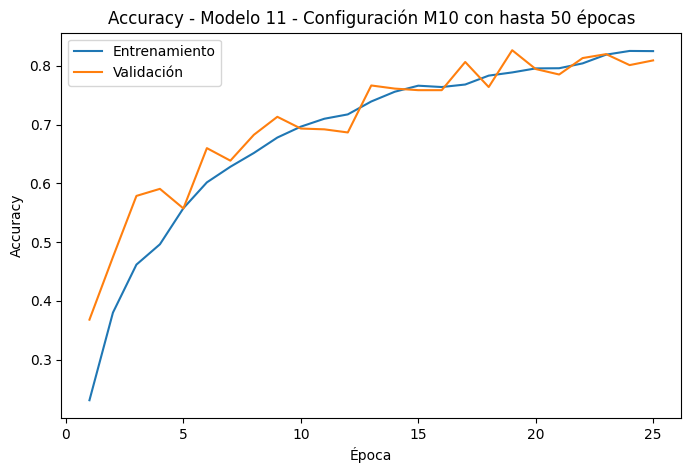

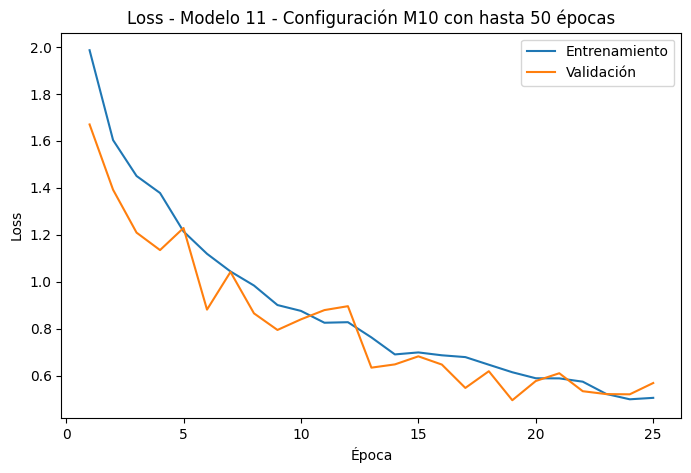

In [74]:
EPOCHS_MODELO11 = 50

modelo_11 = crear_modelo_8()

history_11 = modelo_11.fit(
    train_gen_b4,
    validation_data=val_gen_b4,
    epochs=EPOCHS_MODELO11,
    callbacks=crear_callbacks_bloque3()
)

graficar_historial(history_11, "Modelo 11 - Configuración M10 con hasta 50 épocas")

In [75]:
resultado_11 = obtener_metricas(
    "Modelo 11 - Config. M10 + entrenamiento extendido", modelo_11, history_11, test_gen_b4
)
resultado_11["Bloque"] = "Bloque 4 - 500 imágenes + augmentation refinado"

df_comparacion_final = pd.concat(
    [df_comparacion_final, pd.DataFrame([resultado_11])], ignore_index=True
)

df_comparacion_final.sort_values("Test accuracy", ascending=False)

,Modelo,Mejor val_accuracy,Menor val_loss,Test accuracy,Test loss,Épocas entrenadas,Bloque
9,Modelo 10 - Arq. M8 + 1000 img/clase,0.862667,0.420378,0.844000,0.458377,30,Bloque 4 - 1000 imágenes + augmentation refinado
10,Modelo 11 - Config. M10 + entrenamiento extendido,0.826667,0.495313,0.821333,0.534955,25,Bloque 4 - 500 imágenes + augmentation refinado
7,Modelo 8 - CNN profunda + augmentation,0.830667,0.488556,0.818667,0.555000,30,Bloque 3 - 500 imágenes + augmentation
8,Modelo 9 - CNN profunda + BatchNorm + aug + Re...,0.804000,0.570366,0.806667,0.581682,30,Bloque 3 - 500 imágenes + augmentation
6,Modelo 7 - Arquitectura M6 + augmentation,0.793333,0.573265,0.782667,0.647786,30,Bloque 3 - 500 imágenes + augmentation
5,Modelo 6 - CNN más profunda sin BatchNorm,0.768000,0.689881,0.752000,0.746740,12,Bloque 2 - 500 imágenes por clase
4,Modelo 5 - CNN + Dropout suave + LR menor,0.742667,0.762794,0.725333,0.798244,12,Bloque 2 - 500 imágenes por clase
0,Modelo 1 - CNN simple,0.662222,0.966623,0.706667,0.870919,8,Bloque 1 - 300 imágenes por clase
3,Modelo 4 - CNN base con 500 imágenes,0.722667,0.801595,0.690667,0.867768,12,Bloque 2 - 500 imágenes por clase
1,Modelo 2 - CNN + Dropout,0.520000,1.525639,0.282222,1.883321,3,Bloque 1 - 300 imágenes por clase


24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 187ms/step


<Figure size 1000x1000 with 0 Axes>

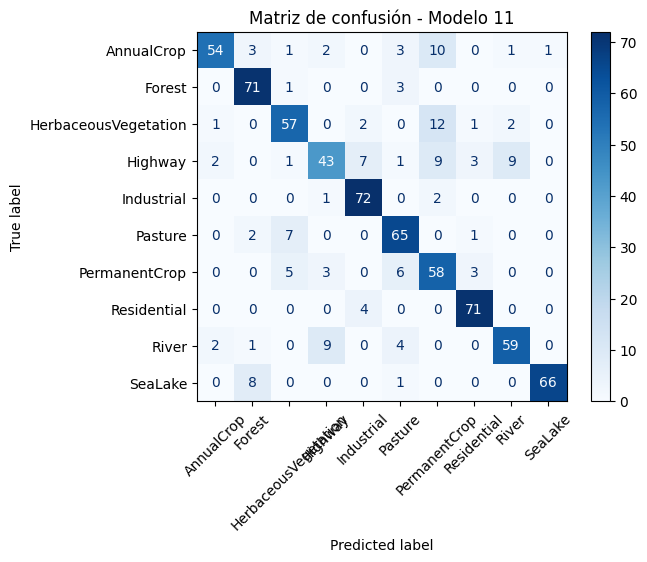

                      precision    recall  f1-score   support

          AnnualCrop       0.92      0.72      0.81        75
              Forest       0.84      0.95      0.89        75
HerbaceousVegetation       0.79      0.76      0.78        75
             Highway       0.74      0.57      0.65        75
          Industrial       0.85      0.96      0.90        75
             Pasture       0.78      0.87      0.82        75
       PermanentCrop       0.64      0.77      0.70        75
         Residential       0.90      0.95      0.92        75
               River       0.83      0.79      0.81        75
             SeaLake       0.99      0.88      0.93        75

            accuracy                           0.82       750
           macro avg       0.83      0.82      0.82       750
        weighted avg       0.83      0.82      0.82       750



In [76]:
test_gen_b4.reset()

preds_11 = modelo_11.predict(test_gen_b4)
y_pred_11 = np.argmax(preds_11, axis=1)
y_true_11 = test_gen_b4.classes
clases_11 = list(test_gen_b4.class_indices.keys())

cm_11 = confusion_matrix(y_true_11, y_pred_11)

plt.figure(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_11, display_labels=clases_11)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión - Modelo 11")
plt.show()

print(classification_report(y_true_11, y_pred_11, target_names=clases_11))

### Conclusión del Modelo 11

El Modelo 11 alcanzó una **accuracy de prueba de 0.8213**, sin superar al Modelo 10 (0.8440) a pesar de tener la misma configuración y un techo de épocas mayor.

Observaciones:

- **El EarlyStopping funcionó correctamente**: la menor loss de validación se registró en la época 19 (0.4953) y, tras 6 épocas sin mejora, el entrenamiento se detuvo en la época 25, restaurando los pesos de la época 19 (mejor val_accuracy: 0.8267). El entrenamiento extendido no fue el problema.
- Lo que explica el resultado es la **variabilidad entre corridas**: aunque la configuración es idéntica a la del Modelo 10, las transformaciones del data augmentation son aleatorias y cada entrenamiento recorre una trayectoria distinta. Comparando las curvas, esta corrida quedó por debajo de la del Modelo 10 desde las primeras épocas y nunca alcanzó su nivel. Con augmentation, diferencias de ±2-3 puntos entre corridas idénticas son esperables.
- El reporte por clase confirma la diferencia: **Highway cayó a F1 0.65 (recall 0.57)**, contra 0.79 del Modelo 10, con confusiones repartidas hacia River (9 casos), PermanentCrop (9) e Industrial (7). PermanentCrop también bajó (0.70 vs 0.76). En cambio, Residential mejoró (0.92 vs 0.86).

Conclusión del experimento: **extender el techo de épocas no produjo mejora**, porque el factor dominante a esta escala no es el tiempo de entrenamiento sino la variabilidad inherente al augmentation aleatorio. Este resultado es valioso metodológicamente: muestra que una única corrida no garantiza reproducir un resultado, y que el **Modelo 10 se confirma como el mejor modelo del trabajo**. Una mejora futura sería fijar la semilla de las transformaciones o promediar varias corridas.

## Experimento complementario: comparación con un modelo preentrenado

La consigna permite usar modelos preentrenados **como experimento complementario y/o comparativo**. Con ese único propósito, se entrena una cabeza de clasificación sobre **MobileNetV2 con pesos de ImageNet y base congelada** (la base no se entrena: solo se ajusta la capa final).

El objetivo no es reemplazar la CNN propia, sino **dimensionar la brecha** entre un modelo entrenado desde cero con ~3.500 imágenes y uno que aprovecha características visuales aprendidas sobre millones de imágenes. Esta referencia permite contextualizar los resultados en las conclusiones: si la CNN propia se acerca al preentrenado, el diseño y el augmentation están funcionando bien; si la brecha es grande, indica cuánto margen aporta el conocimiento previo frente a los datos limitados.

Se usan los mismos generadores y el mismo conjunto de prueba, para que la comparación sea directa.

/tmp/ipykernel_3162/757951473.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 25s 180ms/step - accuracy: 0.4931 - loss: 1.5670 - val_accuracy: 0.6893 - val_loss: 0.9524
Epoch 2/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 18s 161ms/step - accuracy: 0.6451 - loss: 1.0493 - val_accuracy: 0.7320 - val_loss: 0.7600
Epoch 3/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 21s 191ms/step - accuracy: 0.7089 - loss: 0.8859 - val_accuracy: 0.7680 - val_loss: 0.6807
Epoch 4/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 17s 152ms/step - accuracy: 0.7237 - loss: 0.7985 - val_accuracy: 0.8040 - val_loss: 0.6173
Epoch 5/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 17s 152ms/step - accuracy: 0.7531 - loss: 0.7461 - val_accuracy: 0.7973 - val_loss: 0.5971
Epoch 6/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 19s 169ms/step - accuracy: 0.7646 - loss: 0.7107 - val_accuracy: 0.7947 - val_loss: 0.6054
Epoch 7/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 17s 154ms/step - accuracy: 0.7671 - loss: 0.6853 - val_accuracy: 0.7880 - val_loss: 0.6020
Epoch 8/12
110/110 ━━━━━━━━━━━━━━━

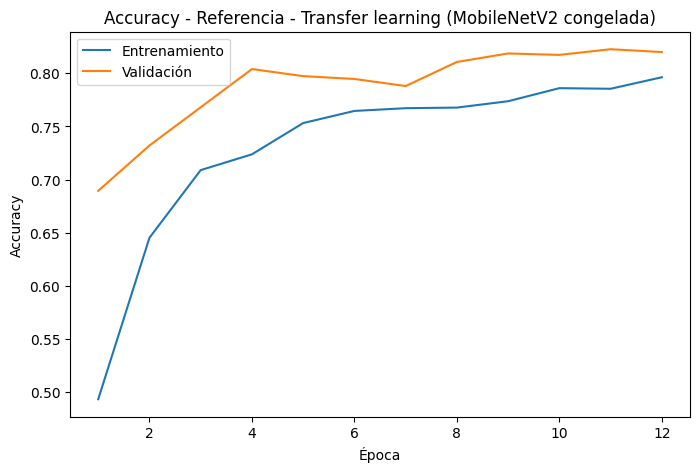

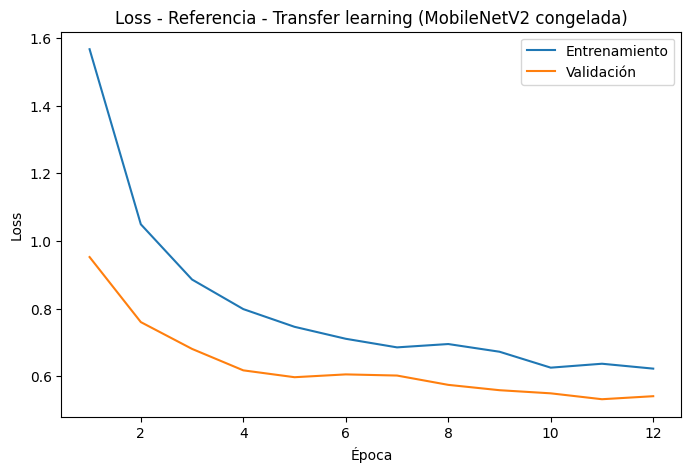

Test accuracy transfer learning: 0.7960


In [73]:
# Experimento complementario (permitido por la consigna): transfer learning con MobileNetV2
# Solo como referencia comparativa, NO como solución principal.

base = tf.keras.applications.MobileNetV2(
    input_shape=(64, 64, 3), include_top=False, weights="imagenet"
)
base.trainable = False  # se congela la base preentrenada

modelo_tl = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.30),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

modelo_tl.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy", metrics=["accuracy"]
)

history_tl = modelo_tl.fit(
    train_gen_b4, validation_data=val_gen_b4,
    epochs=12, callbacks=crear_callbacks_bloque3()
)

graficar_historial(history_tl, "Referencia - Transfer learning (MobileNetV2 congelada)")
test_loss_tl, test_acc_tl = modelo_tl.evaluate(test_gen_b4, verbose=0)
print(f"Test accuracy transfer learning: {test_acc_tl:.4f}")

### Conclusión del experimento comparativo con transfer learning

El modelo de referencia con MobileNetV2 congelada alcanzó una **accuracy de prueba de 0.7960**, entrenando solamente su capa de clasificación final durante 12 épocas.

Observaciones:

- La convergencia fue **muchísimo más rápida** que la de los modelos propios: en la primera época ya alcanzó 0.689 de accuracy de validación, un nivel que a los modelos entrenados desde cero les tomó entre 8 y 10 épocas. Esto refleja el valor de las características visuales preaprendidas sobre millones de imágenes.
- Sin embargo, el modelo se **estancó alrededor de 0.80-0.82 de validación** a partir de la época 4, sin lograr mejorar más: las características de ImageNet (fotografías convencionales de objetos) no están especializadas en imágenes satelitales cenitales, y la base congelada no puede adaptarse a ellas. Además, los pesos preentrenados están optimizados para entradas de 224×224 píxeles, y al usarse con imágenes de 64×64 su efectividad se reduce.
- El resultado más relevante de esta comparación: **la CNN propia entrenada desde cero (Modelo 10, 0.8440) superó al modelo preentrenado (0.7960) en casi 5 puntos**. Esto valida el trabajo de diseño experimental realizado: una arquitectura ajustada al problema, con un esquema de augmentation específicamente fundamentado en la naturaleza de las imágenes satelitales, puede superar a un modelo genérico preentrenado cuando este no se adapta al dominio.

Esta comparación es solo una referencia: un transfer learning completo (con *fine-tuning* de la base) probablemente superaría a ambos, pero excede el alcance de la consigna, que exige una CNN entrenada desde cero como solución principal.

In [79]:
# Corrección de etiquetas: el Modelo 10 se entrenó con 500 imágenes por clase
# (110 steps/época = 3.520 imágenes de entrenamiento), no con 1.000.

df_comparacion_final["Modelo"] = df_comparacion_final["Modelo"].str.replace(
    "Modelo 10 - Arq. M8 + 1000 img/clase",
    "Modelo 10 - Arq. M8 + augmentation refinado",
    regex=False
)

df_comparacion_final["Bloque"] = df_comparacion_final["Bloque"].str.replace(
    "Bloque 4 - 1000 imágenes + augmentation refinado",
    "Bloque 4 - 500 imágenes + augmentation refinado",
    regex=False
)

df_comparacion_final.sort_values("Test accuracy", ascending=False)

,Modelo,Mejor val_accuracy,Menor val_loss,Test accuracy,Test loss,Épocas entrenadas,Bloque
11,Modelo 10 - Arq. M8,0.862667,0.420378,0.844000,0.458377,30,Bloque 4 - 500 imágenes + augmentation refinado
12,Modelo 10 - Arq. M8 + augmentation refinado,0.862667,0.420378,0.844000,0.458377,30,Bloque 4 - 500 imágenes + augmentation refinado
9,Modelo 10 - Arq. M8 + augmentation refinado,0.862667,0.420378,0.844000,0.458377,30,Bloque 4 - 500 imágenes + augmentation refinado
10,Modelo 11 - Config. M10 + entrenamiento extendido,0.826667,0.495313,0.821333,0.534955,25,Bloque 4 - 500 imágenes + augmentation refinado
7,Modelo 8 - CNN profunda + augmentation,0.830667,0.488556,0.818667,0.555000,30,Bloque 3 - 500 imágenes + augmentation
8,Modelo 9 - CNN profunda + BatchNorm + aug + Re...,0.804000,0.570366,0.806667,0.581682,30,Bloque 3 - 500 imágenes + augmentation
6,Modelo 7 - Arquitectura M6 + augmentation,0.793333,0.573265,0.782667,0.647786,30,Bloque 3 - 500 imágenes + augmentation
5,Modelo 6 - CNN más profunda sin BatchNorm,0.768000,0.689881,0.752000,0.746740,12,Bloque 2 - 500 imágenes por clase
4,Modelo 5 - CNN + Dropout suave + LR menor,0.742667,0.762794,0.725333,0.798244,12,Bloque 2 - 500 imágenes por clase
0,Modelo 1 - CNN simple,0.662222,0.966623,0.706667,0.870919,8,Bloque 1 - 300 imágenes por clase


# Resumen general y cierre de la segunda entrega

Se consolidan los resultados de los 11 modelos entrenados desde cero a lo largo de los cuatro bloques experimentales, junto con la referencia de transfer learning. Se presentan: la tabla completa de métricas, la comparación gráfica de todos los modelos, la evolución del mejor resultado por bloque (que resume la historia del proceso experimental), la comparación de curvas de validación de los modelos más relevantes y el análisis de errores del modelo final.

In [85]:
# Eliminar filas duplicadas del Modelo 10 y unificar nombres

df_comparacion_final = df_comparacion_final.drop_duplicates(
    subset=["Modelo"], keep="last"
).reset_index(drop=True)

# Asegurar que el nombre del Modelo 10 esté unificado
df_comparacion_final["Modelo"] = df_comparacion_final["Modelo"].replace({
    "Modelo 10 - Arq. M8": "Modelo 10 - Arq. M8 + augmentation refinado",
    "Modelo 10 - Arq. M8 + 1000 img/clase": "Modelo 10 - Arq. M8 + augmentation refinado",
})

df_comparacion_final["Bloque"] = df_comparacion_final["Bloque"].replace({
    "Bloque 4 - 1000 imágenes + augmentation refinado": "Bloque 4 - 500 imágenes + augmentation refinado",
})

# Por si quedaron duplicados después del rename
df_comparacion_final = df_comparacion_final.drop_duplicates(
    subset=["Modelo"], keep="last"
).reset_index(drop=True)

df_comparacion_final.sort_values("Test accuracy", ascending=False)

,Modelo,Mejor val_accuracy,Menor val_loss,Test accuracy,Test loss,Épocas entrenadas,Bloque
10,Modelo 10 - Arq. M8 + augmentation refinado,0.862667,0.420378,0.844000,0.458377,30,Bloque 4 - 500 imágenes + augmentation refinado
9,Modelo 11 - Config. M10 + entrenamiento extendido,0.826667,0.495313,0.821333,0.534955,25,Bloque 4 - 500 imágenes + augmentation refinado
7,Modelo 8 - CNN profunda + augmentation,0.830667,0.488556,0.818667,0.555000,30,Bloque 3 - 500 imágenes + augmentation
8,Modelo 9 - CNN profunda + BatchNorm + aug + Re...,0.804000,0.570366,0.806667,0.581682,30,Bloque 3 - 500 imágenes + augmentation
6,Modelo 7 - Arquitectura M6 + augmentation,0.793333,0.573265,0.782667,0.647786,30,Bloque 3 - 500 imágenes + augmentation
5,Modelo 6 - CNN más profunda sin BatchNorm,0.768000,0.689881,0.752000,0.746740,12,Bloque 2 - 500 imágenes por clase
4,Modelo 5 - CNN + Dropout suave + LR menor,0.742667,0.762794,0.725333,0.798244,12,Bloque 2 - 500 imágenes por clase
0,Modelo 1 - CNN simple,0.662222,0.966623,0.706667,0.870919,8,Bloque 1 - 300 imágenes por clase
3,Modelo 4 - CNN base con 500 imágenes,0.722667,0.801595,0.690667,0.867768,12,Bloque 2 - 500 imágenes por clase
1,Modelo 2 - CNN + Dropout,0.520000,1.525639,0.282222,1.883321,3,Bloque 1 - 300 imágenes por clase


In [86]:
# Tabla resumen final: todos los modelos ordenados por test accuracy

df_resumen = df_comparacion_final.sort_values("Test accuracy", ascending=False).reset_index(drop=True)
df_resumen.index = df_resumen.index + 1
df_resumen.index.name = "Ranking"

# Fila de referencia: transfer learning (no compite como modelo del trabajo)
print(f"Referencia externa - Transfer learning MobileNetV2 (congelada): test accuracy = {test_acc_tl:.4f}\n")

df_resumen.style.format({
    "Mejor val_accuracy": "{:.4f}",
    "Menor val_loss": "{:.4f}",
    "Test accuracy": "{:.4f}",
    "Test loss": "{:.4f}"
}).background_gradient(subset=["Test accuracy"], cmap="Greens")

Referencia externa - Transfer learning MobileNetV2 (congelada): test accuracy = 0.7960



,Modelo,Mejor val_accuracy,Menor val_loss,Test accuracy,Test loss,Épocas entrenadas,Bloque
Ranking,,,,,,,
1,Modelo 10 - Arq. M8 + augmentation refinado,0.8627,0.4204,0.8440,0.4584,30,Bloque 4 - 500 imágenes + augmentation refinado
2,Modelo 11 - Config. M10 + entrenamiento extendido,0.8267,0.4953,0.8213,0.5350,25,Bloque 4 - 500 imágenes + augmentation refinado
3,Modelo 8 - CNN profunda + augmentation,0.8307,0.4886,0.8187,0.5550,30,Bloque 3 - 500 imágenes + augmentation
4,Modelo 9 - CNN profunda + BatchNorm + aug + ReduceLR,0.8040,0.5704,0.8067,0.5817,30,Bloque 3 - 500 imágenes + augmentation
5,Modelo 7 - Arquitectura M6 + augmentation,0.7933,0.5733,0.7827,0.6478,30,Bloque 3 - 500 imágenes + augmentation
6,Modelo 6 - CNN más profunda sin BatchNorm,0.7680,0.6899,0.7520,0.7467,12,Bloque 2 - 500 imágenes por clase
7,Modelo 5 - CNN + Dropout suave + LR menor,0.7427,0.7628,0.7253,0.7982,12,Bloque 2 - 500 imágenes por clase
8,Modelo 1 - CNN simple,0.6622,0.9666,0.7067,0.8709,8,Bloque 1 - 300 imágenes por clase
9,Modelo 4 - CNN base con 500 imágenes,0.7227,0.8016,0.6907,0.8678,12,Bloque 2 - 500 imágenes por clase


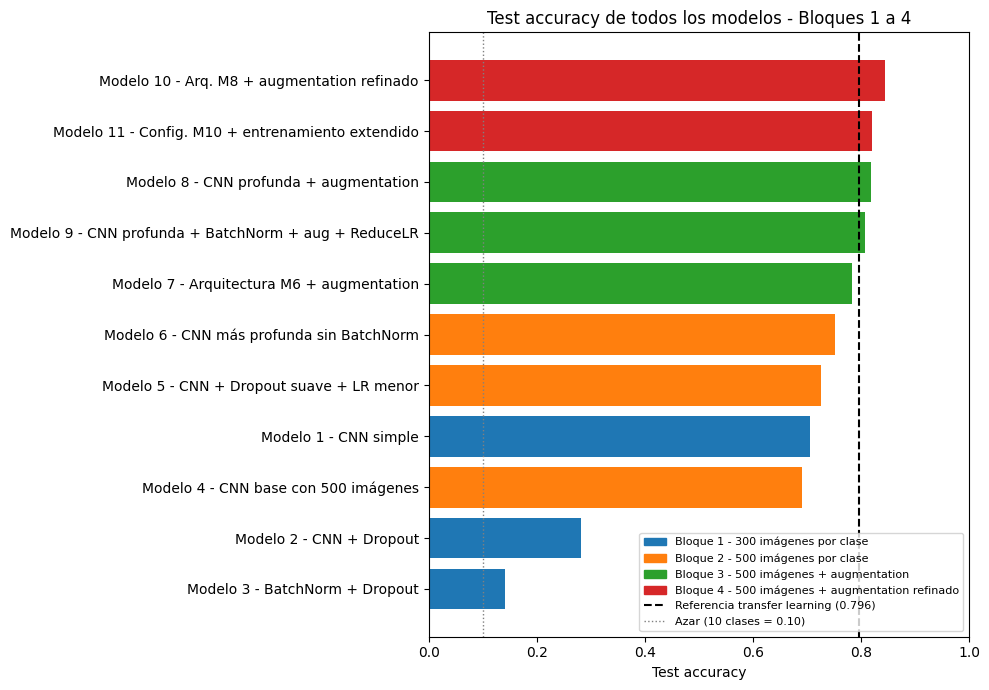

In [87]:
# Comparación gráfica de todos los modelos, coloreados por bloque

colores_bloque = {
    "Bloque 1 - 300 imágenes por clase": "tab:blue",
    "Bloque 2 - 500 imágenes por clase": "tab:orange",
    "Bloque 3 - 500 imágenes + augmentation": "tab:green",
    "Bloque 4 - 500 imágenes + augmentation refinado": "tab:red",
}

df_plot = df_comparacion_final.sort_values("Test accuracy", ascending=True)
colores = [colores_bloque.get(b, "gray") for b in df_plot["Bloque"]]

plt.figure(figsize=(10, 7))
plt.barh(df_plot["Modelo"], df_plot["Test accuracy"], color=colores)
plt.axvline(test_acc_tl, color="black", linestyle="--", linewidth=1.5,
            label=f"Referencia transfer learning ({test_acc_tl:.3f})")
plt.axvline(0.10, color="gray", linestyle=":", linewidth=1,
            label="Azar (10 clases = 0.10)")
plt.title("Test accuracy de todos los modelos - Bloques 1 a 4")
plt.xlabel("Test accuracy")
plt.xlim(0, 1)

import matplotlib.patches as mpatches
leyenda_bloques = [mpatches.Patch(color=c, label=b) for b, c in colores_bloque.items()]
plt.legend(handles=leyenda_bloques + plt.gca().get_legend_handles_labels()[0],
           loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### Análisis del gráfico comparativo

El gráfico muestra de un vistazo la separación entre los cuatro bloques experimentales: los modelos del Bloque 1 (azul) ocupan ambos extremos —el baseline funcional (M1, 0.71) y los dos peores experimentos del trabajo (M2 y M3, por debajo de 0.30)—, lo que evidencia cuán sensible es el rendimiento a la configuración cuando hay pocos datos. El Bloque 2 (naranja) se ubica en el rango 0.69-0.75, el Bloque 3 (verde) salta al rango 0.78-0.82, y el Bloque 4 (rojo) corona la lista en 0.82-0.84.

Tres observaciones a destacar:

- **El salto más grande del trabajo se produjo al agregar data augmentation** (transición del bloque naranja al verde), que confirma la hipótesis con la que se abrió el Bloque 3.
- **La línea negra de referencia (transfer learning, 0.796) queda atravesando el bloque verde**: los tres modelos del Bloque 3 oscilan alrededor de ella, y los del Bloque 4 la superan claramente. La CNN propia, bien diseñada, supera al modelo preentrenado genérico en este dominio.
- **La distancia entre la línea de azar (0.10) y los modelos M2 y M3** es muy chica, lo que recuerda que esos experimentos fallidos no fueron simplemente "peores": la red prácticamente no logró aprender. Conservarlos en el trabajo aporta valor metodológico porque muestran cómo el mismo concepto (regularización, BatchNorm) puede ser útil o destructivo según las condiciones.

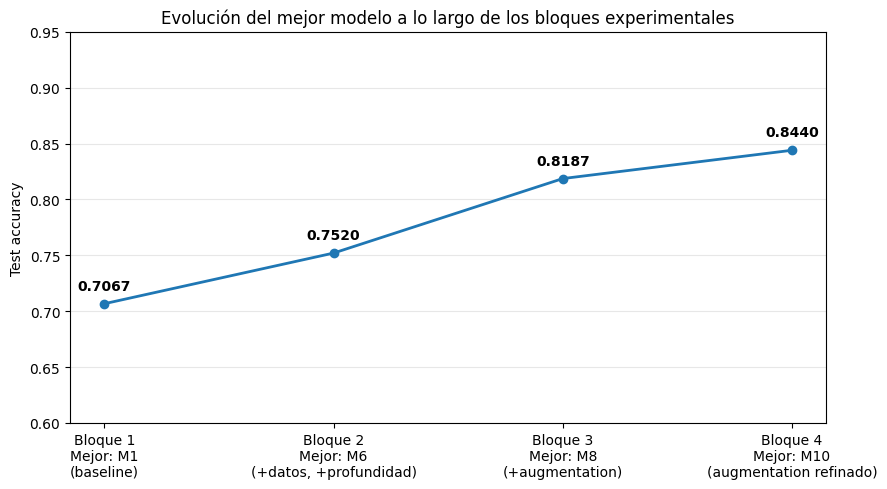

In [82]:
# Progresión del mejor resultado de cada bloque experimental

mejores_por_bloque = (
    df_comparacion_final.loc[
        df_comparacion_final.groupby("Bloque")["Test accuracy"].idxmax()
    ]
    .sort_values("Test accuracy")
)

etiquetas = [
    "Bloque 1\nMejor: M1\n(baseline)",
    "Bloque 2\nMejor: M6\n(+datos, +profundidad)",
    "Bloque 3\nMejor: M8\n(+augmentation)",
    "Bloque 4\nMejor: M10\n(augmentation refinado)",
]

plt.figure(figsize=(9, 5))
plt.plot(etiquetas, mejores_por_bloque["Test accuracy"], marker="o", linewidth=2)

for x, y in zip(etiquetas, mejores_por_bloque["Test accuracy"]):
    plt.annotate(f"{y:.4f}", (x, y), textcoords="offset points",
                 xytext=(0, 10), ha="center", fontweight="bold")

plt.title("Evolución del mejor modelo a lo largo de los bloques experimentales")
plt.ylabel("Test accuracy")
plt.ylim(0.6, 0.95)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Análisis de la evolución por bloque

Este gráfico es la "historia" del trabajo condensada en cuatro puntos: cada uno representa el mejor modelo de su bloque, y la línea muestra que **cada cambio metodológico produjo una mejora cuantificable**.

Las cuatro transiciones:

- **Bloque 1 → Bloque 2 (+4.5 puntos):** pasar de 300 a 500 imágenes por clase y aplicar profundidad moderada con regularización suave. La mejora es modesta porque la arquitectura ya era razonable; el aporte fue mayormente la cantidad de datos.
- **Bloque 2 → Bloque 3 (+6.7 puntos):** introducción del data augmentation. **Este es el salto más grande del trabajo** y valida la decisión metodológica de Probar augmentation antes de seguir agrandando la red.
- **Bloque 3 → Bloque 4 (+2.5 puntos):** refinamiento del augmentation (rotaciones de 90° exactos sin bordes artificiales). Mejora menor pero significativa, conseguida sin tocar la arquitectura ni los datos.

Las pendientes decrecientes (4.5 → 6.7 → 2.5) sugieren rendimientos decrecientes en cada nueva intervención sobre la misma muestra de 500 imágenes. La próxima ganancia significativa probablemente requiera el salto a más datos reales, lo que motiva el plan para la entrega final.

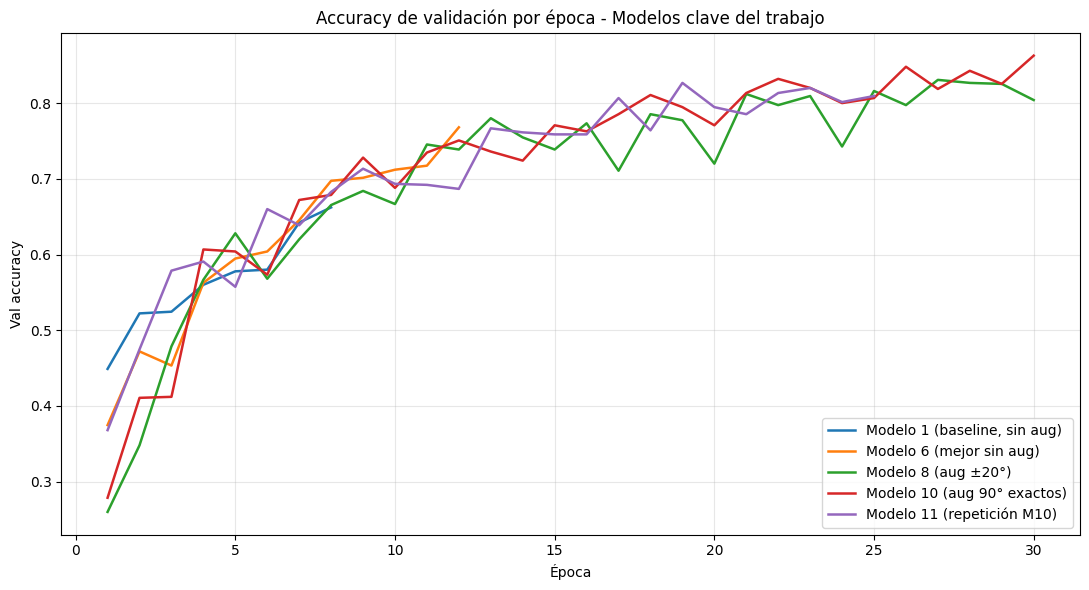

In [83]:
# Comparación de las curvas de validación de los modelos más relevantes

historiales_clave = {
    "Modelo 1 (baseline, sin aug)": history_1,
    "Modelo 6 (mejor sin aug)": history_6,
    "Modelo 8 (aug ±20°)": history_8,
    "Modelo 10 (aug 90° exactos)": history_10,
    "Modelo 11 (repetición M10)": history_11,
}

plt.figure(figsize=(11, 6))

for nombre, h in historiales_clave.items():
    val_acc = h.history["val_accuracy"]
    plt.plot(range(1, len(val_acc) + 1), val_acc, label=nombre, linewidth=1.8)

plt.title("Accuracy de validación por época - Modelos clave del trabajo")
plt.xlabel("Época")
plt.ylabel("Val accuracy")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Análisis de las curvas de validación

La comparación de las curvas cuenta una historia que la tabla no muestra: **cómo cada cambio afectó el comportamiento durante el entrenamiento**, no solo el resultado final.

- **Modelo 1 (azul) y Modelo 6 (naranja), sin augmentation**: convergen rápido (en 8-12 épocas), pero se estancan en el rango 0.66-0.77. Las curvas son cortas porque el EarlyStopping los detuvo: ya no había nada que aprender de los datos vistos.
- **Modelo 8 (verde), augmentation ±20°**: arranca más bajo (0.26 en la primera época vs. 0.45 del Modelo 1), pero **sigue subiendo durante 30 épocas** hasta superar el 0.83. El augmentation hace cada época más difícil pero permite seguir aprendiendo más tiempo.
- **Modelo 10 (rojo), augmentation 90° exactos**: trayectoria muy parecida a la del Modelo 8 pero termina más alto (0.86), confirmando el beneficio del refinamiento.
- **Modelo 11 (violeta), repetición del Modelo 10**: arranca mejor que el Modelo 10 hasta la época 13 y luego queda por debajo. Es el ejemplo visual más claro de la **variabilidad entre corridas idénticas** con augmentation aleatorio: dos modelos con la misma configuración exploran trayectorias distintas.

Observación general: las tres curvas con augmentation son visiblemente más "ruidosas" (oscilan más entre épocas) que las dos sin augmentation, porque la validación se enfrenta a un modelo que aprendió de datos transformados de forma distinta en cada época. Esto es esperable y no indica problemas.

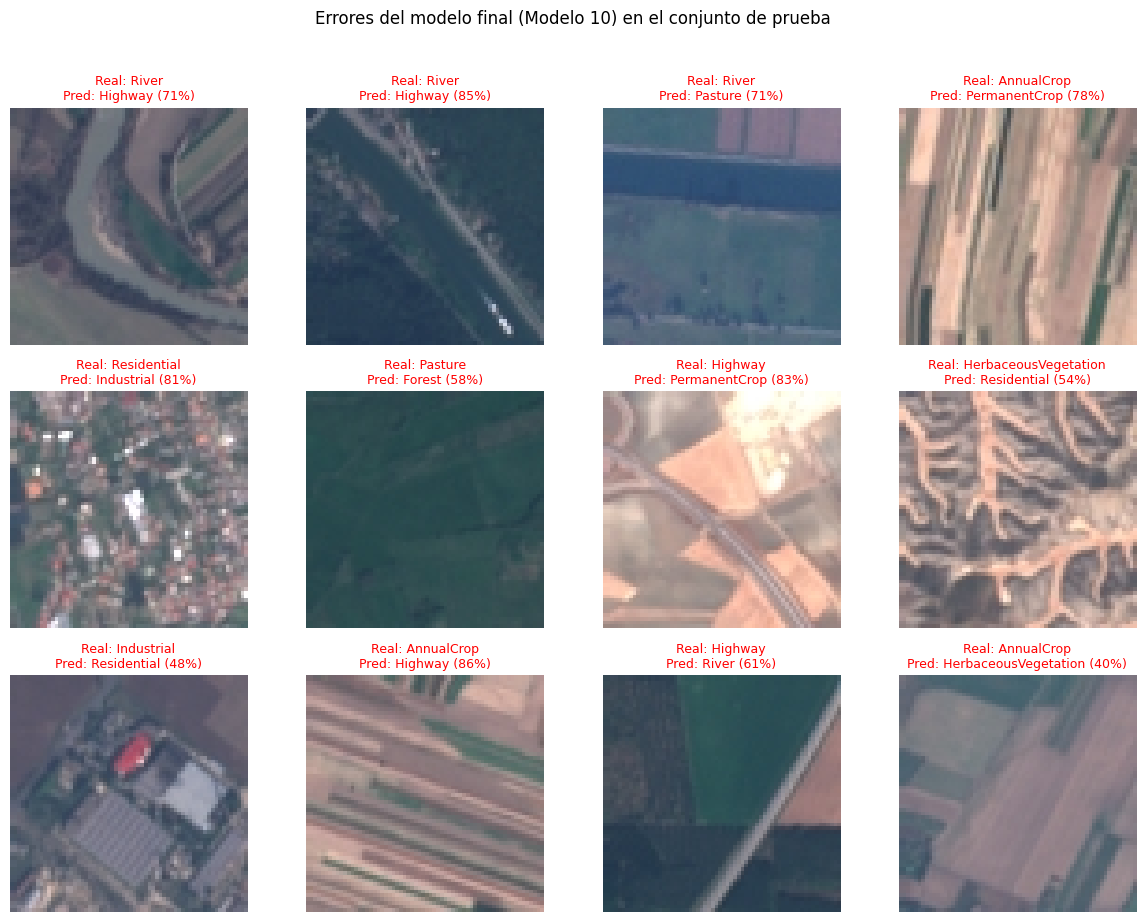

In [84]:
# Visualización de imágenes MAL clasificadas por el modelo final (Modelo 10)

test_gen_b4.reset()
preds_final = modelo_10.predict(test_gen_b4, verbose=0)
y_pred_f = np.argmax(preds_final, axis=1)
y_true_f = test_gen_b4.classes
clases_f = list(test_gen_b4.class_indices.keys())

indices_error = np.where(y_pred_f != y_true_f)[0][:12]
filepaths_test = test_df_b4["filepath"].values

from PIL import Image as PILImage

plt.figure(figsize=(12, 9))
for i, idx in enumerate(indices_error):
    plt.subplot(3, 4, i + 1)
    img = PILImage.open(test_gen_b4.filepaths[idx])
    plt.imshow(img)
    confianza = preds_final[idx][y_pred_f[idx]]
    plt.title(f"Real: {clases_f[y_true_f[idx]]}\nPred: {clases_f[y_pred_f[idx]]} ({confianza:.0%})",
              fontsize=9, color="red")
    plt.axis("off")

plt.suptitle("Errores del modelo final (Modelo 10) en el conjunto de prueba", y=1.02)
plt.tight_layout()
plt.show()

### Análisis de los errores del modelo final

La inspección visual de los errores confirma que **los fallos del modelo se concentran en confusiones objetivamente difíciles a 64×64 píxeles**, no en errores aleatorios:

- **River → Highway** (3 ejemplos visibles, los más frecuentes en la matriz de confusión): los tres muestran cursos de agua estrechos, sinuosos o cubiertos de vegetación. Visualmente comparten la característica clave —una franja alargada y de color uniforme cortando el terreno— con las autopistas. A esta resolución, distinguir "agua sinuosa" de "asfalto" requeriría detalles que el modelo no puede ver.
- **AnnualCrop ↔ PermanentCrop ↔ HerbaceousVegetation**: aparecen varias imágenes de parcelas rectangulares con tonos de verde y marrón muy parecidos. La distinción entre estos tres tipos de cobertura vegetal depende del estado fenológico del cultivo (algo que cambia con la estación), no solo de su apariencia espacial.
- **Confianza calibrada**: el modelo no acierta y "le pifia con confianza absoluta". En varios errores la confianza está por debajo del 60% (HerbaceousVegetation→Residential 54%, Pasture→Forest 58%, AnnualCrop→HerbaceousVegetation 40%, Residential→Industrial 48%), indicando que el modelo "duda" en los casos genuinamente ambiguos. Es una señal positiva de calibración: las predicciones de alta confianza tienden a ser correctas, y las dudas se reflejan en probabilidades intermedias.

Estos errores marcan el techo natural del problema en esta resolución y motivan, para la entrega final, escalar a más datos reales (que aporten más ejemplos de los casos límite) y eventualmente analizar si trabajar con resoluciones mayores podría aliviar las confusiones más persistentes.

# Conclusiones finales

## Resumen del proceso experimental

Se entrenaron **11 redes neuronales convolucionales desde cero** a lo largo de cuatro bloques experimentales, modificando de manera controlada una variable por vez, más un experimento comparativo con transfer learning. La progresión del mejor modelo por bloque cuenta la historia del trabajo:

| Bloque | Cambio introducido | Mejor modelo | Test accuracy |
|---|---|---|---|
| 1 (300 img/clase) | Línea base | Modelo 1 | 0.7067 |
| 2 (500 img/clase) | Más datos + profundidad moderada | Modelo 6 | 0.7520 |
| 3 (+ augmentation) | Data augmentation geométrico | Modelo 8 | 0.8187 |
| 4 (aug. refinado) | Rotaciones de 90° exactos | **Modelo 10** | **0.8440** |

Hallazgos principales del proceso:

1. **La regularización debe ser proporcional a los datos**: el Dropout agresivo (Modelo 2) y BatchNormalization con pocos datos y épocas (Modelo 3) empeoraron drásticamente el rendimiento, mientras que las mismas técnicas en condiciones adecuadas funcionaron (Modelos 5 y 9).
2. **El data augmentation fue el factor de mejora más importante** (+6.7 puntos entre el Modelo 6 y el Modelo 8), y su refinamiento específico para imágenes satelitales (rotaciones de 90° exactos, sin bordes artificiales) agregó +2.5 puntos más, beneficiando especialmente a las clases con patrones lineales (Highway pasó de F1 0.70 a 0.79; River, de 0.74 a 0.83).
3. **Existe variabilidad entre corridas**: el Modelo 11, con configuración idéntica al 10, obtuvo 2.3 puntos menos por la aleatoriedad del augmentation. Una única corrida no garantiza reproducir un resultado exacto.
4. **La CNN propia superó a la referencia preentrenada**: el Modelo 10 (0.8440) le ganó a MobileNetV2 congelada (0.7960), demostrando que una arquitectura ajustada al problema, con augmentation fundamentado en la naturaleza del dominio, puede superar a características genéricas preaprendidas.

## Mejor modelo obtenido

El modelo final de esta entrega es el **Modelo 10**: CNN de bloques convolucionales dobles (32→64→128 filtros, ~1.3 millones de parámetros), Dropout moderado, Adam con learning rate 0.0005, entrenada con augmentation de rotaciones de 90° exactos, flips y zoom suave. Alcanzó **0.8440 de accuracy de prueba** con curvas de entrenamiento y validación unidas durante todo el proceso (sin sobreajuste).

Por clase: las mejores son **SeaLake (F1 0.96), Forest (0.92) e Industrial (0.91)**; las más difíciles, **HerbaceousVegetation y PermanentCrop (0.76)** y el recall de **AnnualCrop (0.71)**, cuyas confusiones se concentran entre los distintos tipos de vegetación y cultivo, la frontera visual más difusa del problema a 64×64 píxeles.

## Limitaciones identificadas

- **Muestra reducida**: 500 de ~2.500-3.000 imágenes disponibles por clase, por limitaciones de cómputo en Google Colab.
- **Baja resolución** (64×64): limita los rasgos finos, en especial para las clases de cultivos y vegetación.
- **Una sola corrida por experimento**: como mostró el Modelo 11, los resultados tienen una variabilidad de ±2-3 puntos que no se cuantificó con repeticiones.
- Las curvas del Modelo 10 no habían convergido del todo al cortarse en la época 30.

## Plan para la entrega final

1. **Escalar la configuración ganadora (Modelo 10) a 1.000 imágenes por clase**, dado que el aumento de datos fue el factor de mejora más consistente. No se usará el dataset completo (27.000 imágenes) por el costo computacional y los rendimientos decrecientes esperados.
2. Entrenar con un techo de épocas mayor, aprovechando que el augmentation previene el sobreajuste.
3. Evaluación final completa del modelo: matriz de confusión, métricas por clase y análisis de errores.
